# Road Damage and Pothole Detection
## Academic Project Notebook

**Objective:** Train and evaluate a YOLOv8 object-detection model to identify potholes in road images, then demonstrate the model through a Streamlit prototype.

**Workflow:** dataset inspection → annotation validation → GPU setup → model training → evaluation → prediction inspection → Streamlit deployment.

**Reproducibility note:** This notebook records the project's development and diagnostics. Some cells install packages, resume training, write configuration files, or run evaluation. Read each cell before rerunning it; do not rerun training or evaluation cells unless intentionally repeating that experiment.

In [1]:
from pathlib import Path


project_dir = Path.home() / "RoadDamageDetection"


folders = [
    "data",
    "notebooks",
    "models",
    "results",
    "reports"
]

project_dir.mkdir(parents=True, exist_ok=True)

for folder in folders:
    (project_dir / folder).mkdir(exist_ok=True)

print("Project folder created successfully!")
print("Location:", project_dir)

print("\nProject folders:")
for folder in project_dir.iterdir():
    if folder.is_dir():
        print(" -", folder.name)

Project folder created successfully!
Location: C:\Users\thesh\RoadDamageDetection

Project folders:
 - data
 - models
 - notebooks
 - reports
 - results


## 1. Environment and Dependencies

The project uses Python, PyTorch, Ultralytics YOLO, OpenCV, and Streamlit. The environment verification below records package versions and whether CUDA is available. Package installation is included for reproducibility, but it may be skipped if the required packages are already installed.

In [1]:
%pip install ultralytics streamlit pandas matplotlib pillow opencv-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch
import ultralytics
import cv2
import streamlit as st

print("YOLO/Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)
print("CUDA available:", torch.cuda.is_available())

print("\nInstallation verification successful!")

YOLO/Ultralytics version: 8.4.190
PyTorch version: 2.14.1+cpu
OpenCV version: 5.0.0
CUDA available: False

Installation verification successful!


## 2. Dataset Overview

The dataset is stored under `RoadDamageDetection/data` and uses separate `train`, `valid`, and `test` splits. The task has one detection class: `pothole`. The following cells inspect the folder structure and dataset YAML configuration.

In [3]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"
data_dir = project_dir / "data"

print("Dataset exists:", data_dir.exists())
print("Configuration exists:", (data_dir / "data.yaml").exists())

for split in ["train", "valid", "test"]:
    split_dir = data_dir / split

    if split_dir.exists():
        print(f"\n{split.upper()} folder:")

        for item in split_dir.iterdir():
            print(" ", item.name)
    else:
        print(f"\n{split.upper()} folder not found!")

Dataset exists: True
Configuration exists: True

TRAIN folder:
  images
  labels
  labels.cache

VALID folder:
  images
  labels
  labels.cache

TEST folder:
  images
  labels


In [4]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"
yaml_path = project_dir / "data" / "data.yaml"

print(yaml_path.read_text(encoding="utf-8"))

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['pothole']

roboflow:
  workspace: brad-dwyer
  project: pothole-voxrl
  version: 1
  license: ODbL v1.0
  url: https://universe.roboflow.com/brad-dwyer/pothole-voxrl/dataset/1


In [5]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"
data_dir = project_dir / "data"

for split in ["train", "valid", "test"]:
    images_dir = data_dir / split / "images"
    labels_dir = data_dir / split / "labels"

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ]

    labels = list(labels_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))


TRAIN
Images: 465
Label files: 465

VALID
Images: 133
Label files: 133

TEST
Images: 67
Label files: 67


In [6]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"
yaml_path = project_dir / "data" / "data.yaml"

print("========== DATASET CONFIGURATION ==========")
print(yaml_path.read_text(encoding="utf-8"))

========== DATASET CONFIGURATION ==========
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['pothole']

roboflow:
  workspace: brad-dwyer
  project: pothole-voxrl
  version: 1
  license: ODbL v1.0
  url: https://universe.roboflow.com/brad-dwyer/pothole-voxrl/dataset/1


## 3. Annotation Quality Checks

YOLO detection labels use the format `class_id x_center y_center width height`, with normalized coordinates. The following checks look for malformed rows, out-of-range coordinates, and boxes with non-positive width or height. Annotation problems should be documented rather than silently repaired.

In [7]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"
data_dir = project_dir / "data"

label_dirs = {
    "train": data_dir / "train" / "labels",
    "valid": data_dir / "valid" / "labels",
    "test": data_dir / "test" / "labels",
}

total_boxes = 0
total_empty = 0
total_invalid = 0

for split, label_dir in label_dirs.items():
    boxes = 0
    empty_files = 0
    invalid_lines = 0

    for file in label_dir.glob("*.txt"):
        lines = file.read_text(encoding="utf-8").splitlines()

        if not lines:
            empty_files += 1
            continue

        for line in lines:
            parts = line.split()

            try:
                values = [float(x) for x in parts]

                valid = (
                    len(values) == 5
                    and values[0] == 0
                    and all(0 <= x <= 1 for x in values[1:])
                    and values[3] > 0
                    and values[4] > 0
                )

                if valid:
                    boxes += 1
                else:
                    invalid_lines += 1

            except ValueError:
                invalid_lines += 1

    total_boxes += boxes
    total_empty += empty_files
    total_invalid += invalid_lines

    print(f"\n{split.upper()}")
    print("Valid bounding boxes:", boxes)
    print("Empty label files:", empty_files)
    print("Invalid annotation lines:", invalid_lines)

print("\n========== TOTALS ==========")
print("Valid bounding boxes:", total_boxes)
print("Empty label files:", total_empty)
print("Invalid annotation lines:", total_invalid)


TRAIN
Valid bounding boxes: 1256
Empty label files: 0
Invalid annotation lines: 0

VALID
Valid bounding boxes: 330
Empty label files: 0
Invalid annotation lines: 0

TEST
Valid bounding boxes: 153
Empty label files: 0
Invalid annotation lines: 1

========== TOTALS ==========
Valid bounding boxes: 1739
Empty label files: 0
Invalid annotation lines: 1


In [8]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"
test_labels_dir = project_dir / "data" / "test" / "labels"

for file in sorted(test_labels_dir.glob("*.txt")):
    lines = file.read_text(encoding="utf-8").splitlines()

    for line_number, line in enumerate(lines, start=1):
        parts = line.split()

        try:
            values = [float(x) for x in parts]

            valid = (
                len(values) == 5
                and values[0] == 0
                and all(0 <= x <= 1 for x in values[1:])
                and values[3] > 0
                and values[4] > 0
            )

        except ValueError:
            valid = False

        if not valid:
            print("Invalid annotation found!")
            print("File:", file.name)
            print("Line:", line_number)
            print("Content:", repr(line))

Invalid annotation found!
File: img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd.txt
Line: 3
Content: '0 0.68 0.545 0 0.0033333333333333335'


### 3.1 Inspecting the malformed test annotation

One test-label row was found with zero width: `0 0.68 0.545 0 0.0033333333333333335`. A zero-width box is invalid. The original label is preserved; a separate cleaned-label copy excludes this malformed row. The missing ground-truth box was not reconstructed, which remains a limitation of the cleaned-test evaluation.

In [9]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

project_dir = Path.home() / "RoadDamageDetection"
image_path = (
    project_dir / "data" / "test" / "images"
    / "img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd.jpg"
)

print("Image exists:", image_path.exists())

if image_path.exists():
    image = Image.open(image_path)

    print("Image dimensions:", image.size)

    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Test Image: Inspect Pothole Annotation")
    plt.show()
else:
    print("Image not found. Let's list files with a matching name:")
    for path in (project_dir / "data" / "test" / "images").glob("*415*"):
        print(path.name)

Image exists: True
Image dimensions: (400, 300)


C:\Users\thesh\AppData\Local\Temp\ipykernel_28424\295976358.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Image dimensions: (400, 300)


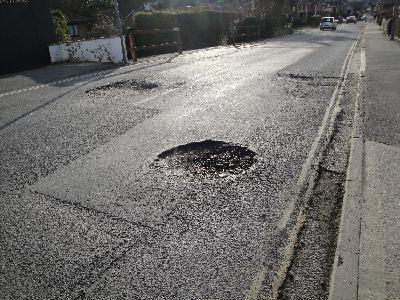

In [10]:
from pathlib import Path
from PIL import Image
from IPython.display import display

project_dir = Path.home() / "RoadDamageDetection"

image_path = (
    project_dir / "data" / "test" / "images"
    / "img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd.jpg"
)

image = Image.open(image_path).convert("RGB")

print("Image dimensions:", image.size)
display(image)

In [11]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"

label_path = (
    project_dir / "data" / "test" / "labels"
    / "img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd.txt"
)

print("Label file:", label_path.name)
print("\nOriginal annotations:\n")

for line_number, line in enumerate(
    label_path.read_text(encoding="utf-8").splitlines(),
    start=1
):
    print(f"Line {line_number}: {line}")

Label file: img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd.txt

Original annotations:

Line 1: 0 0.51125 0.5333333333333333 0.2775 0.15333333333333332
Line 2: 0 0.3 0.29 0.185 0.06
Line 3: 0 0.68 0.545 0 0.0033333333333333335


In [12]:
from pathlib import Path
import shutil

project_dir = Path.home() / "RoadDamageDetection"
data_dir = project_dir / "data"

original_test_labels = data_dir / "test" / "labels"
clean_test_labels = data_dir / "test_labels_clean"


clean_test_labels.mkdir(exist_ok=True)


for label_file in original_test_labels.glob("*.txt"):
    shutil.copy2(label_file, clean_test_labels / label_file.name)


target_name = "img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd.txt"
target_file = clean_test_labels / target_name

lines = target_file.read_text(encoding="utf-8").splitlines()

cleaned_lines = [
    line for line in lines
    if line.strip() != "0 0.68 0.545 0 0.0033333333333333335"
]

target_file.write_text(
    "\n".join(cleaned_lines) + "\n",
    encoding="utf-8"
)

print("Clean test-label copy created:", clean_test_labels)
print("Original label file preserved:", (original_test_labels / target_name).exists())
print("\nCleaned annotations:")
print(target_file.read_text(encoding="utf-8"))

Clean test-label copy created: C:\Users\thesh\RoadDamageDetection\data\test_labels_clean
Original label file preserved: True

Cleaned annotations:
0 0.51125 0.5333333333333333 0.2775 0.15333333333333332
0 0.3 0.29 0.185 0.06



In [13]:
from pathlib import Path
import yaml

project_dir = Path.home() / "RoadDamageDetection"
data_dir = project_dir / "data"

config = {
    "path": str(data_dir.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["pothole"],
}

config_path = data_dir / "data_yolov8.yaml"

with open(config_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("YOLOv8 configuration created:")
print(config_path)
print("\nConfiguration contents:")

with open(config_path, "r", encoding="utf-8") as f:
    print(f.read())

YOLOv8 configuration created:
C:\Users\thesh\RoadDamageDetection\data\data_yolov8.yaml

Configuration contents:
path: C:\Users\thesh\RoadDamageDetection\data
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- pothole



## 4. Training Artifacts and GPU Setup

The project uses the saved YOLOv8 Nano checkpoint and training history. The next cells inspect saved artifacts and verify CUDA availability. The machine used for this project has an NVIDIA GeForce RTX 2050 with 4 GB of VRAM.

In [14]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"
run_dir = project_dir / "results" / "yolov8n_baseline"

print("Training folder exists:", run_dir.exists())

if run_dir.exists():
    for path in sorted(run_dir.rglob("*")):
        if path.is_file() and path.suffix in [".pt", ".csv", ".png"]:
            print(path.relative_to(project_dir))

Training folder exists: True
results\yolov8n_baseline\results.csv
results\yolov8n_baseline\weights\best.pt
results\yolov8n_baseline\weights\last.pt


In [15]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
PyTorch CUDA build: None
CUDA available: False


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch: 2.14.1+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 2050
GPU memory: 4.0 GB


## 5. YOLOv8 Training

The training workflow loads the last checkpoint and can resume training. The resume cell is intentionally kept for reproducibility, but it should only be executed when you explicitly intend to continue training. Training has already completed for 30 epochs; rerunning this section is not required for the final submission.

In [2]:
from pathlib import Path
import torch
from ultralytics import YOLO

# Project paths
project_dir = Path.home() / "RoadDamageDetection"

data_yaml = project_dir / "data" / "data_yolov8.yaml"

checkpoint = (
    project_dir
    / "results"
    / "yolov8n_baseline"
    / "weights"
    / "last.pt"
)

# Verify files
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Dataset configuration exists:", data_yaml.exists())
print("Last checkpoint exists:", checkpoint.exists())

assert data_yaml.exists(), "Dataset configuration not found."
assert checkpoint.exists(), "Training checkpoint not found."

# Load the previous training checkpoint
model = YOLO(str(checkpoint))

print("\nCheckpoint loaded successfully.")
print("Preparing to resume training...")

CUDA available: True
GPU: NVIDIA GeForce RTX 2050
Dataset configuration exists: True
Last checkpoint exists: True

Checkpoint loaded successfully.
Preparing to resume training...


In [3]:
results = model.train(
    resume=True,
    device=0,
    batch=4,
    workers=0
)

Ultralytics 8.4.190  Python-3.11.17 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\thesh\RoadDamageDetection\data\data_yolov8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users\thesh\RoadDamageDetection\results\yolov8n_baseline\weights\last.pt, momen

## 6. Streamlit Application

This cell writes `app.py`, a web prototype that loads `results/yolov8n_baseline/weights/best.pt`, accepts an uploaded road image, displays detections and confidence scores, and offers an annotated-image download. The generated app uses a default confidence threshold of 0.45; users can adjust it in the interface. Rerunning this cell overwrites `app.py`, so only do so when intentionally regenerating the application.

In [4]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"

app_code = r'''
from pathlib import Path
from io import BytesIO

import streamlit as st
from PIL import Image
from ultralytics import YOLO

PROJECT_DIR = Path.home() / "RoadDamageDetection"
MODEL_PATH = (
    PROJECT_DIR
    / "results"
    / "yolov8n_baseline"
    / "weights"
    / "best.pt"
)

st.set_page_config(
    page_title="Road Damage and Pothole Detection",
    page_icon="🚧",
    layout="wide"
)

st.title("Road Damage and Pothole Detection")
st.write("Upload a road image to detect potholes using YOLOv8.")

@st.cache_resource
def load_model():
    if not MODEL_PATH.exists():
        raise FileNotFoundError(f"Model not found: {MODEL_PATH}")
    return YOLO(str(MODEL_PATH))

try:
    model = load_model()
    st.success("YOLOv8 model loaded successfully.")
except Exception as exc:
    st.error(f"Could not load model: {exc}")
    st.stop()

confidence = st.slider(
    "Detection confidence threshold",
    min_value=0.10,
    max_value=0.90,
    value=0.45,
    step=0.05
)

uploaded_file = st.file_uploader(
    "Upload a road image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")

    with st.spinner("Detecting potholes..."):
        result = model.predict(
            source=image,
            imgsz=640,
            conf=confidence,
            device=0,
            verbose=False
        )[0]

    annotated_image = result.plot()[:, :, ::-1]

    original_col, result_col = st.columns(2)

    with original_col:
        st.subheader("Original Image")
        st.image(image, use_container_width=True)

    with result_col:
        st.subheader("Detection Result")
        st.image(annotated_image, use_container_width=True)

    boxes = result.boxes
    count = len(boxes) if boxes is not None else 0

    st.metric("Potholes detected", count)

    if count:
        detections = []

        for index, box in enumerate(boxes, start=1):
            detections.append({
                "Detection": index,
                "Class": result.names[int(box.cls.item())],
                "Confidence": round(float(box.conf.item()), 4),
                "X1": round(float(box.xyxy[0][0].item()), 1),
                "Y1": round(float(box.xyxy[0][1].item()), 1),
                "X2": round(float(box.xyxy[0][2].item()), 1),
                "Y2": round(float(box.xyxy[0][3].item()), 1)
            })

        st.subheader("Detection Details")
        st.dataframe(detections, use_container_width=True)
    else:
        st.info(
            "No potholes detected above this confidence threshold. "
            "This does not guarantee that the road is pothole-free."
        )

    buffer = BytesIO()
    Image.fromarray(annotated_image).save(buffer, format="PNG")

    st.download_button(
        "Download Annotated Image",
        data=buffer.getvalue(),
        file_name="pothole_detection_result.png",
        mime="image/png"
    )

st.caption(
    "Prototype for road inspection assistance. "
    "All detections require human verification."
)
'''

app_path = project_dir / "app.py"
app_path.write_text(app_code, encoding="utf-8")

print("Application created:", app_path)
print("File exists:", app_path.exists())
print("Model exists:", (
    project_dir / "results" / "yolov8n_baseline"
    / "weights" / "best.pt"
).exists())

Application created: C:\Users\thesh\RoadDamageDetection\app.py
File exists: True
Model exists: True


In [5]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"

print("Project directory:", project_dir)
print("\nNotebook files:")

for path in sorted(project_dir.glob("*.ipynb")):
    print("-", path.name)

print("\nImportant project files:")

for relative_path in [
    "data/data.yaml",
    "data/data_yolov8.yaml",
    "results/yolov8n_baseline/results.csv",
    "results/yolov8n_baseline/weights/best.pt",
    "results/yolov8n_test_evaluation",
    "app.py",
]:
    path = project_dir / relative_path
    print(f"{relative_path}: {'Exists' if path.exists() else 'Not found'}")

Project directory: C:\Users\thesh\RoadDamageDetection

Notebook files:

Important project files:
data/data.yaml: Exists
data/data_yolov8.yaml: Exists
results/yolov8n_baseline/results.csv: Exists
results/yolov8n_baseline/weights/best.pt: Exists
results/yolov8n_test_evaluation: Exists
app.py: Exists


In [6]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"

checks = {
    "Best trained model": project_dir / "results/yolov8n_baseline/weights/best.pt",
    "Last training checkpoint": project_dir / "results/yolov8n_baseline/weights/last.pt",
    "Training history": project_dir / "results/yolov8n_baseline/results.csv",
    "Test evaluation results": project_dir / "results/yolov8n_test_evaluation",
    "Streamlit application": project_dir / "app.py",
    "YOLO dataset configuration": project_dir / "data/data_yolov8.yaml",
}

print("PROJECT ARTIFACT CHECK\n")

for name, path in checks.items():
    print(f"{name}: {'OK' if path.exists() else 'MISSING'}")
    print(f"  {path}")

PROJECT ARTIFACT CHECK

Best trained model: OK
  C:\Users\thesh\RoadDamageDetection\results\yolov8n_baseline\weights\best.pt
Last training checkpoint: OK
  C:\Users\thesh\RoadDamageDetection\results\yolov8n_baseline\weights\last.pt
Training history: OK
  C:\Users\thesh\RoadDamageDetection\results\yolov8n_baseline\results.csv
Test evaluation results: OK
  C:\Users\thesh\RoadDamageDetection\results\yolov8n_test_evaluation
Streamlit application: OK
  C:\Users\thesh\RoadDamageDetection\app.py
YOLO dataset configuration: OK
  C:\Users\thesh\RoadDamageDetection\data\data_yolov8.yaml


## 7. Original Test Evaluation and Diagnostics

The following evaluation runs the saved model against the original test split and generates diagnostic plots. Because the test split is also used for error inspection in this development notebook, these results should be described as project evaluation results rather than an untouched, independent benchmark.

In [7]:
from pathlib import Path
from ultralytics import YOLO

project_dir = Path.home() / "RoadDamageDetection"

model_path = (
    project_dir
    / "results"
    / "yolov8n_baseline"
    / "weights"
    / "best.pt"
)

data_yaml = project_dir / "data" / "data_yolov8.yaml"

model = YOLO(str(model_path))

results = model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    workers=0,
    plots=True,
    project=str(project_dir / "results"),
    name="yolov8n_test_analysis",
    exist_ok=True
)

print("\nEvaluation complete.")
print("Precision:", round(float(results.box.mp), 4))
print("Recall:", round(float(results.box.mr), 4))
print("mAP@0.5:", round(float(results.box.map50), 4))
print("mAP@0.5:0.95:", round(float(results.box.map), 4))
print("\nAnalysis files saved to:")
print(project_dir / "results" / "yolov8n_test_analysis")

Ultralytics 8.4.190  Python-3.11.17 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 261.3±397.1 MB/s, size: 61.7 KB)
val: Scanning C:\Users\thesh\RoadDamageDetection\data\test\labels.cache... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 14.0it/s 1.2s0.1s
                   all         67        154      0.742       0.71      0.764      0.498
Speed: 0.6ms preprocess, 7.3ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to C:\Users\thesh\RoadDamageDetection\results\yolov8n_test_analysis

Evaluation complete.
Precision: 0.7422
Recall: 0.7104
mAP@0.5: 0.7636
mAP@0.5:0.95: 0.4975

Analysis files saved to:
C:\Users\thesh\RoadDamageDetection\results\yolov8n_test_analysis


Evaluation plots:

BoxF1_curve.png
BoxP_curve.png
BoxPR_curve.png
BoxR_curve.png
confusion_matrix.png


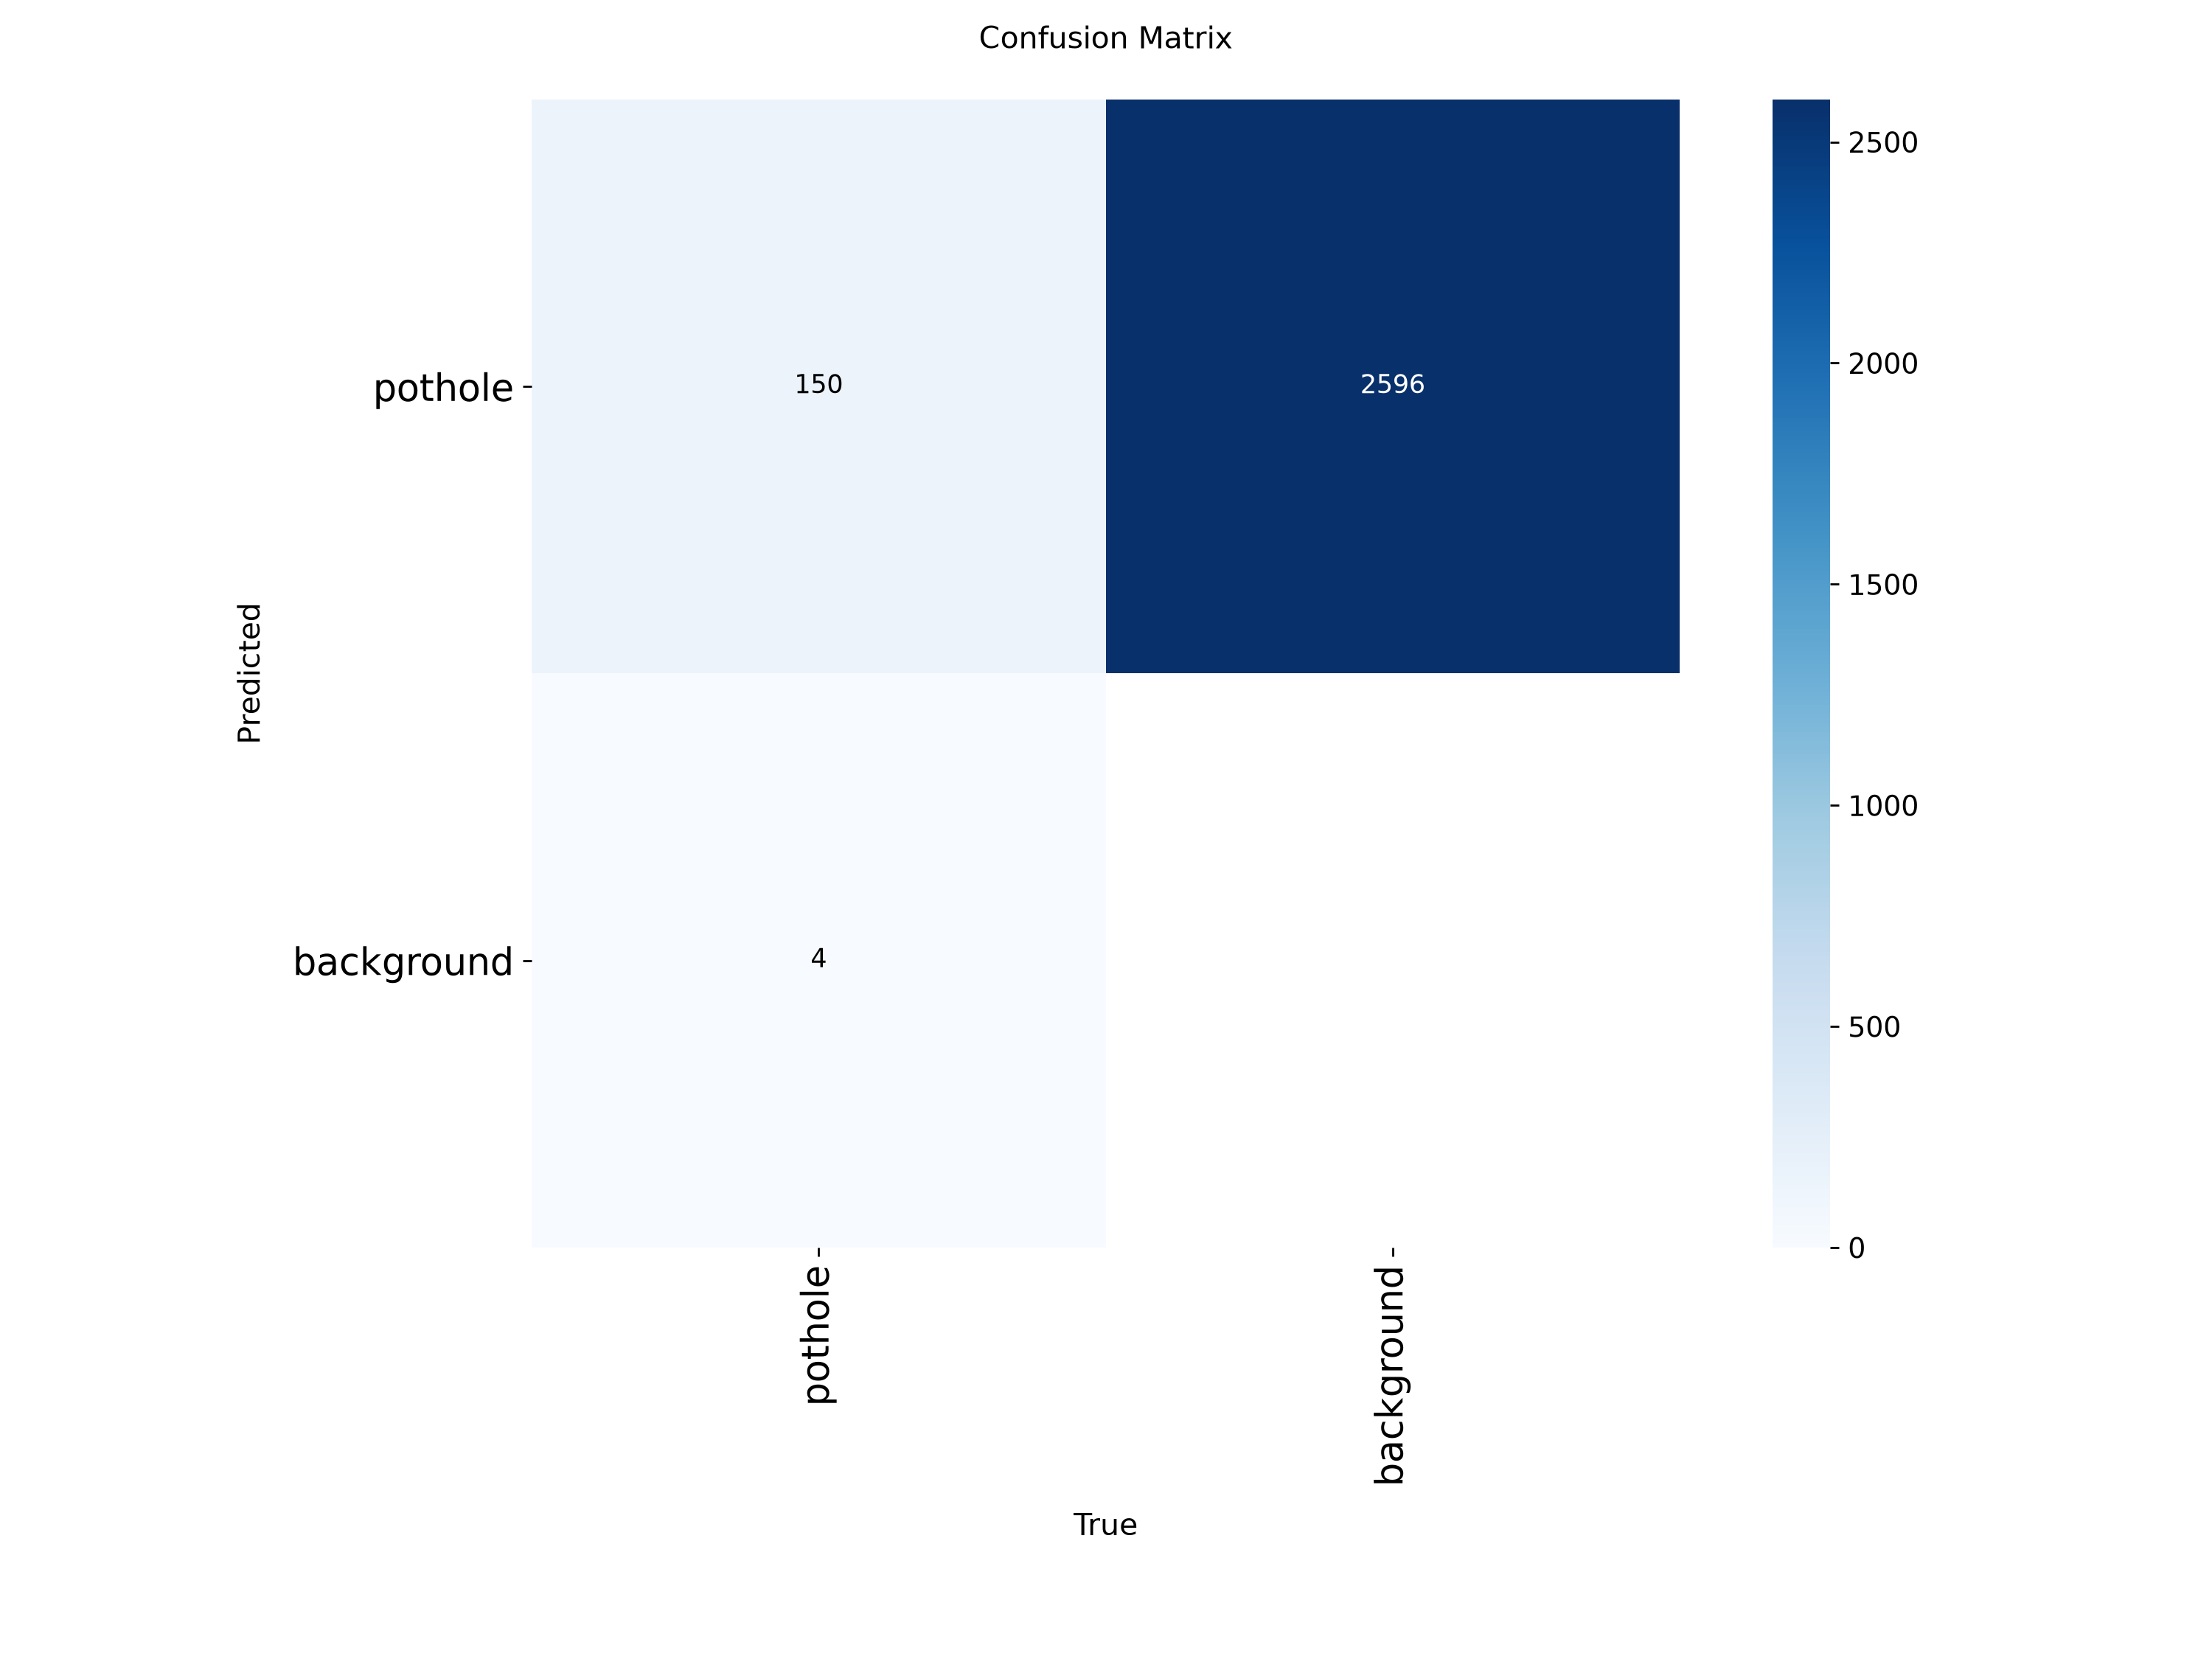

confusion_matrix_normalized.png


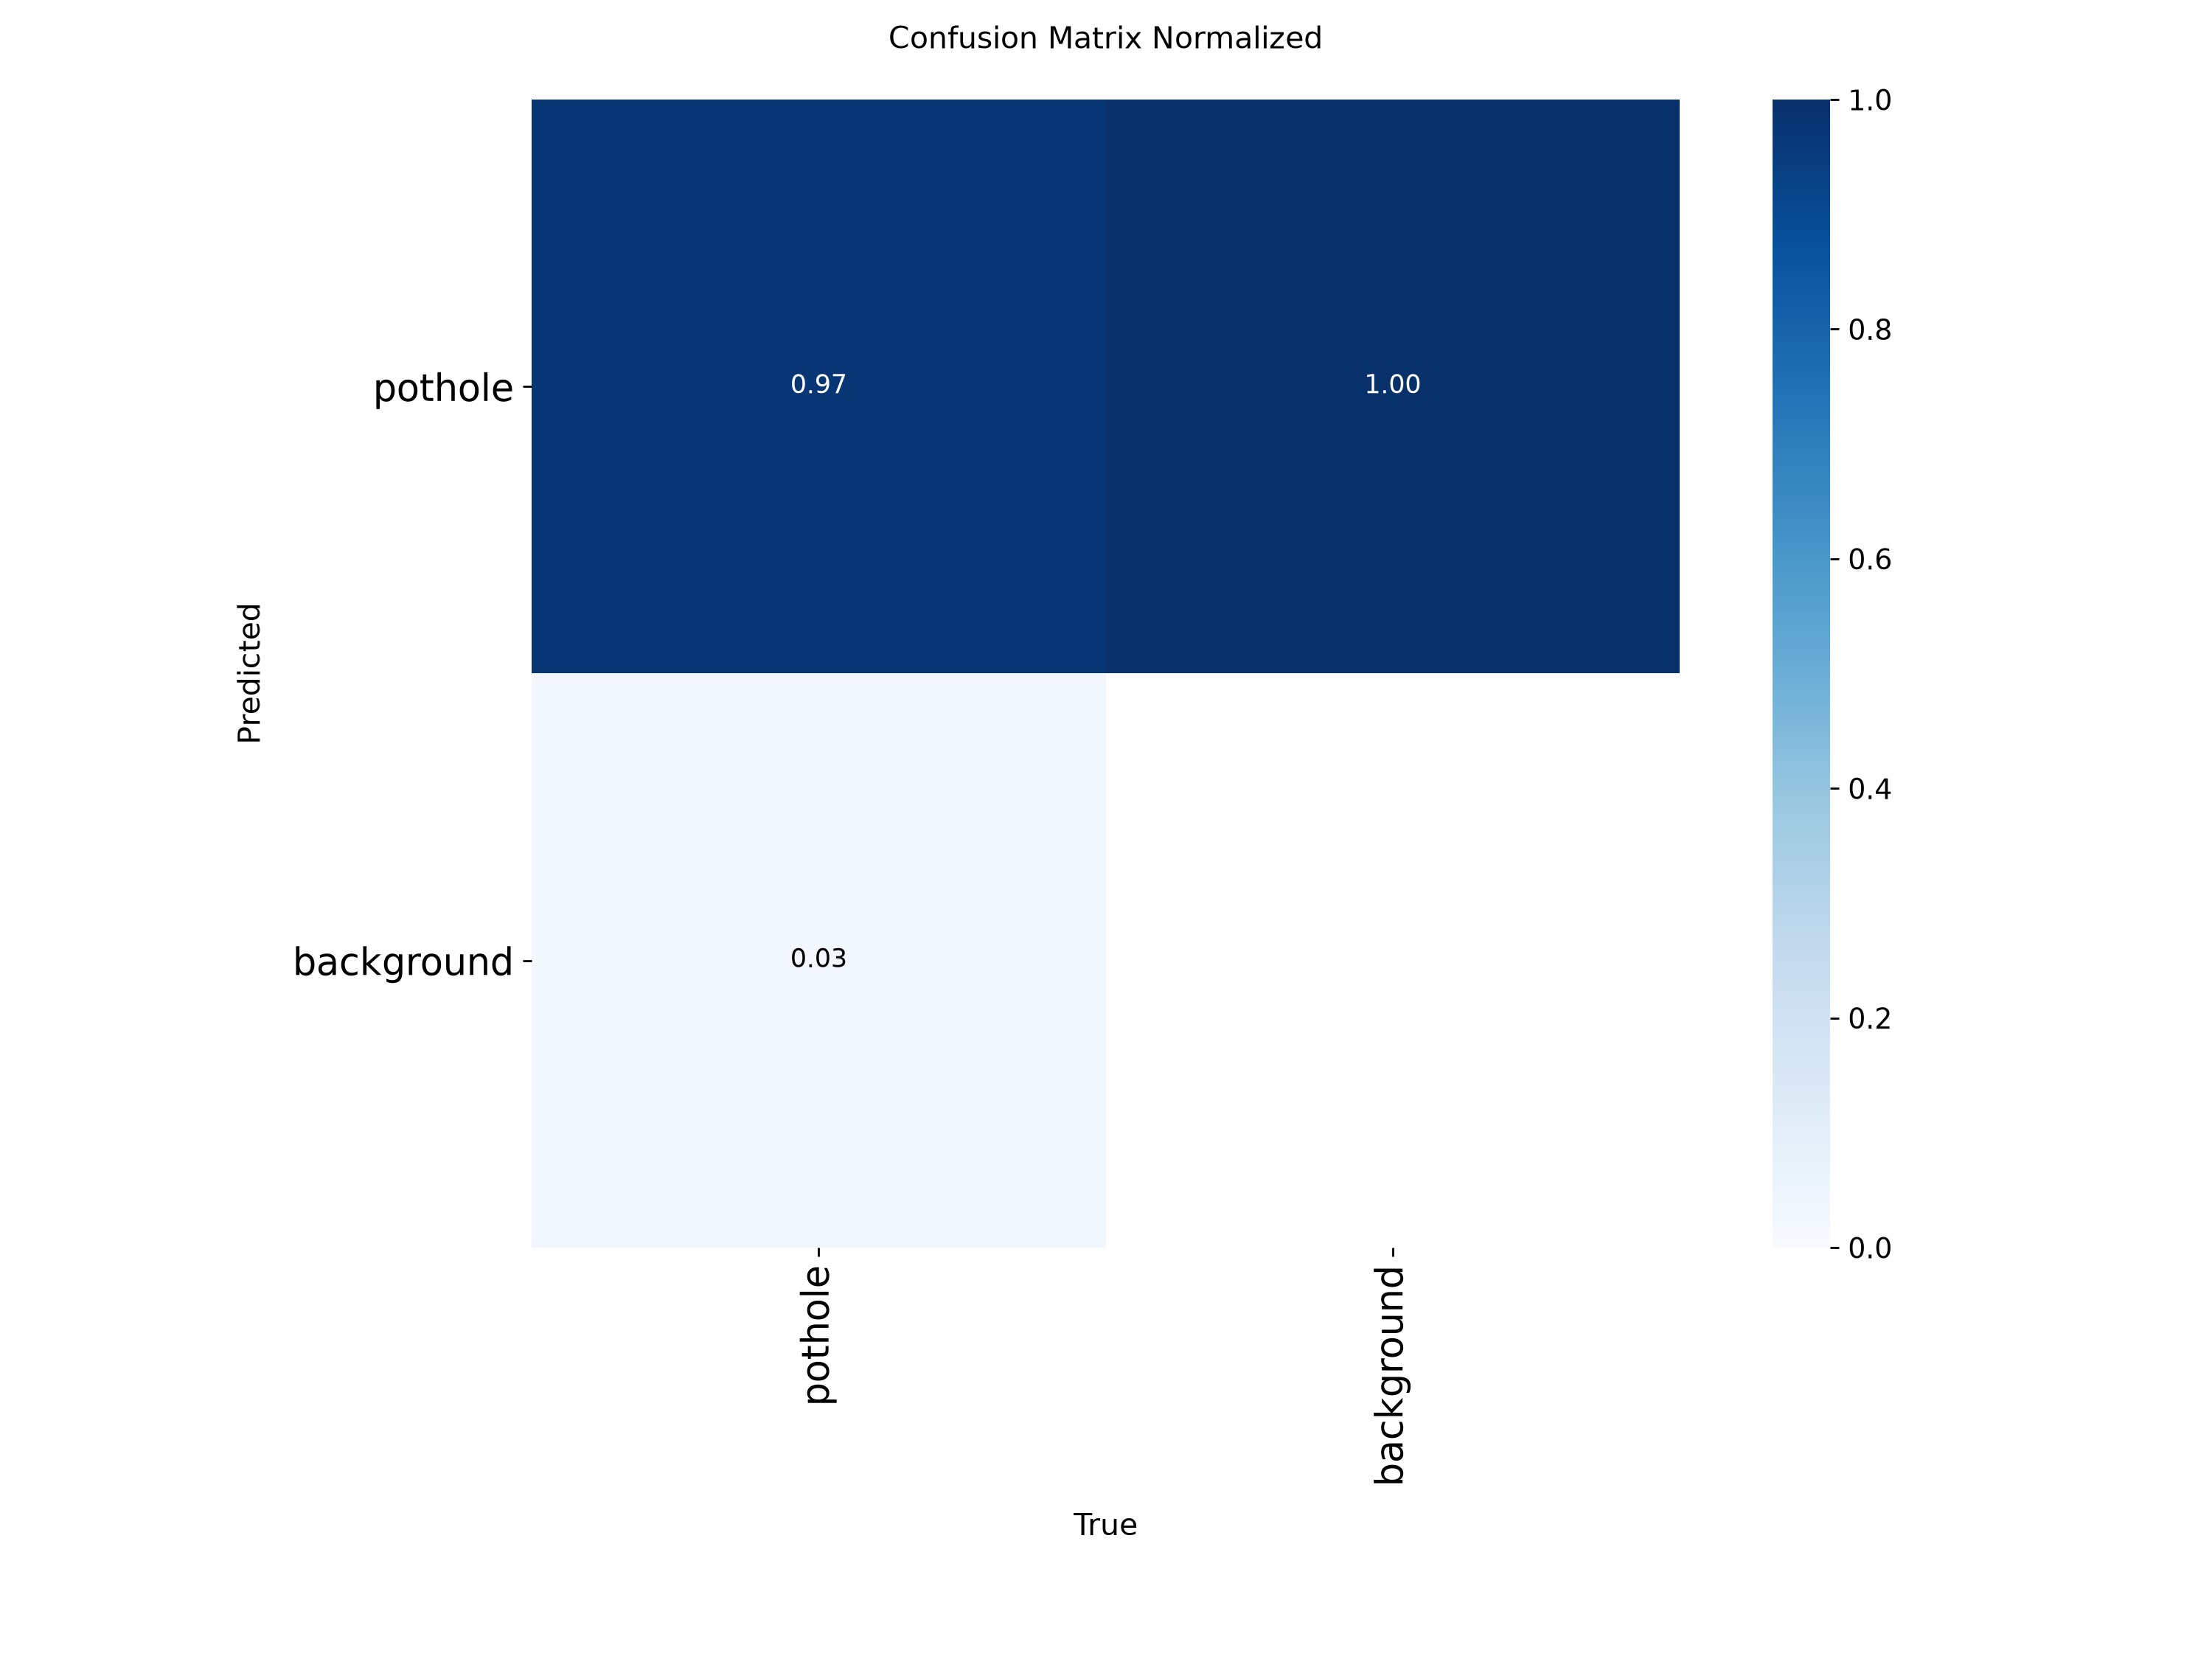

In [8]:
from pathlib import Path
from IPython.display import display, Image

project_dir = Path.home() / "RoadDamageDetection"
analysis_dir = project_dir / "results" / "yolov8n_test_analysis"

print("Evaluation plots:\n")

for path in sorted(analysis_dir.glob("*.png")):
    print(path.name)

    if path.name in [
        "confusion_matrix.png",
        "confusion_matrix_normalized.png",
        "PR_curve.png",
        "F1_curve.png",
        "P_curve.png",
        "R_curve.png",
    ]:
        display(Image(filename=str(path)))

Evaluation files:
BoxF1_curve.png
BoxP_curve.png
BoxPR_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

Training history:
Rows: 30


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,330.549,1.14715,0.93021,1.18888,0.82025,0.66970,0.77582,0.46711,1.34698,1.09856,1.38380,0.000350,0.000350,0.000350
26,27,349.245,1.11456,0.90718,1.18915,0.79374,0.67273,0.76302,0.47627,1.32405,1.10448,1.36120,0.000284,0.000284,0.000284
27,28,366.668,1.10190,0.90325,1.17979,0.82215,0.67576,0.77059,0.47611,1.30563,1.09177,1.35655,0.000218,0.000218,0.000218
28,29,382.146,1.08980,0.85369,1.16724,0.83126,0.67576,0.77933,0.48841,1.28887,1.06853,1.33526,0.000152,0.000152,0.000152
29,30,398.482,1.07648,0.83487,1.16343,0.83812,0.68788,0.77852,0.49138,1.28765,1.08502,1.33888,0.000086,0.000086,0.000086



Available confusion matrix images:
confusion_matrix.png


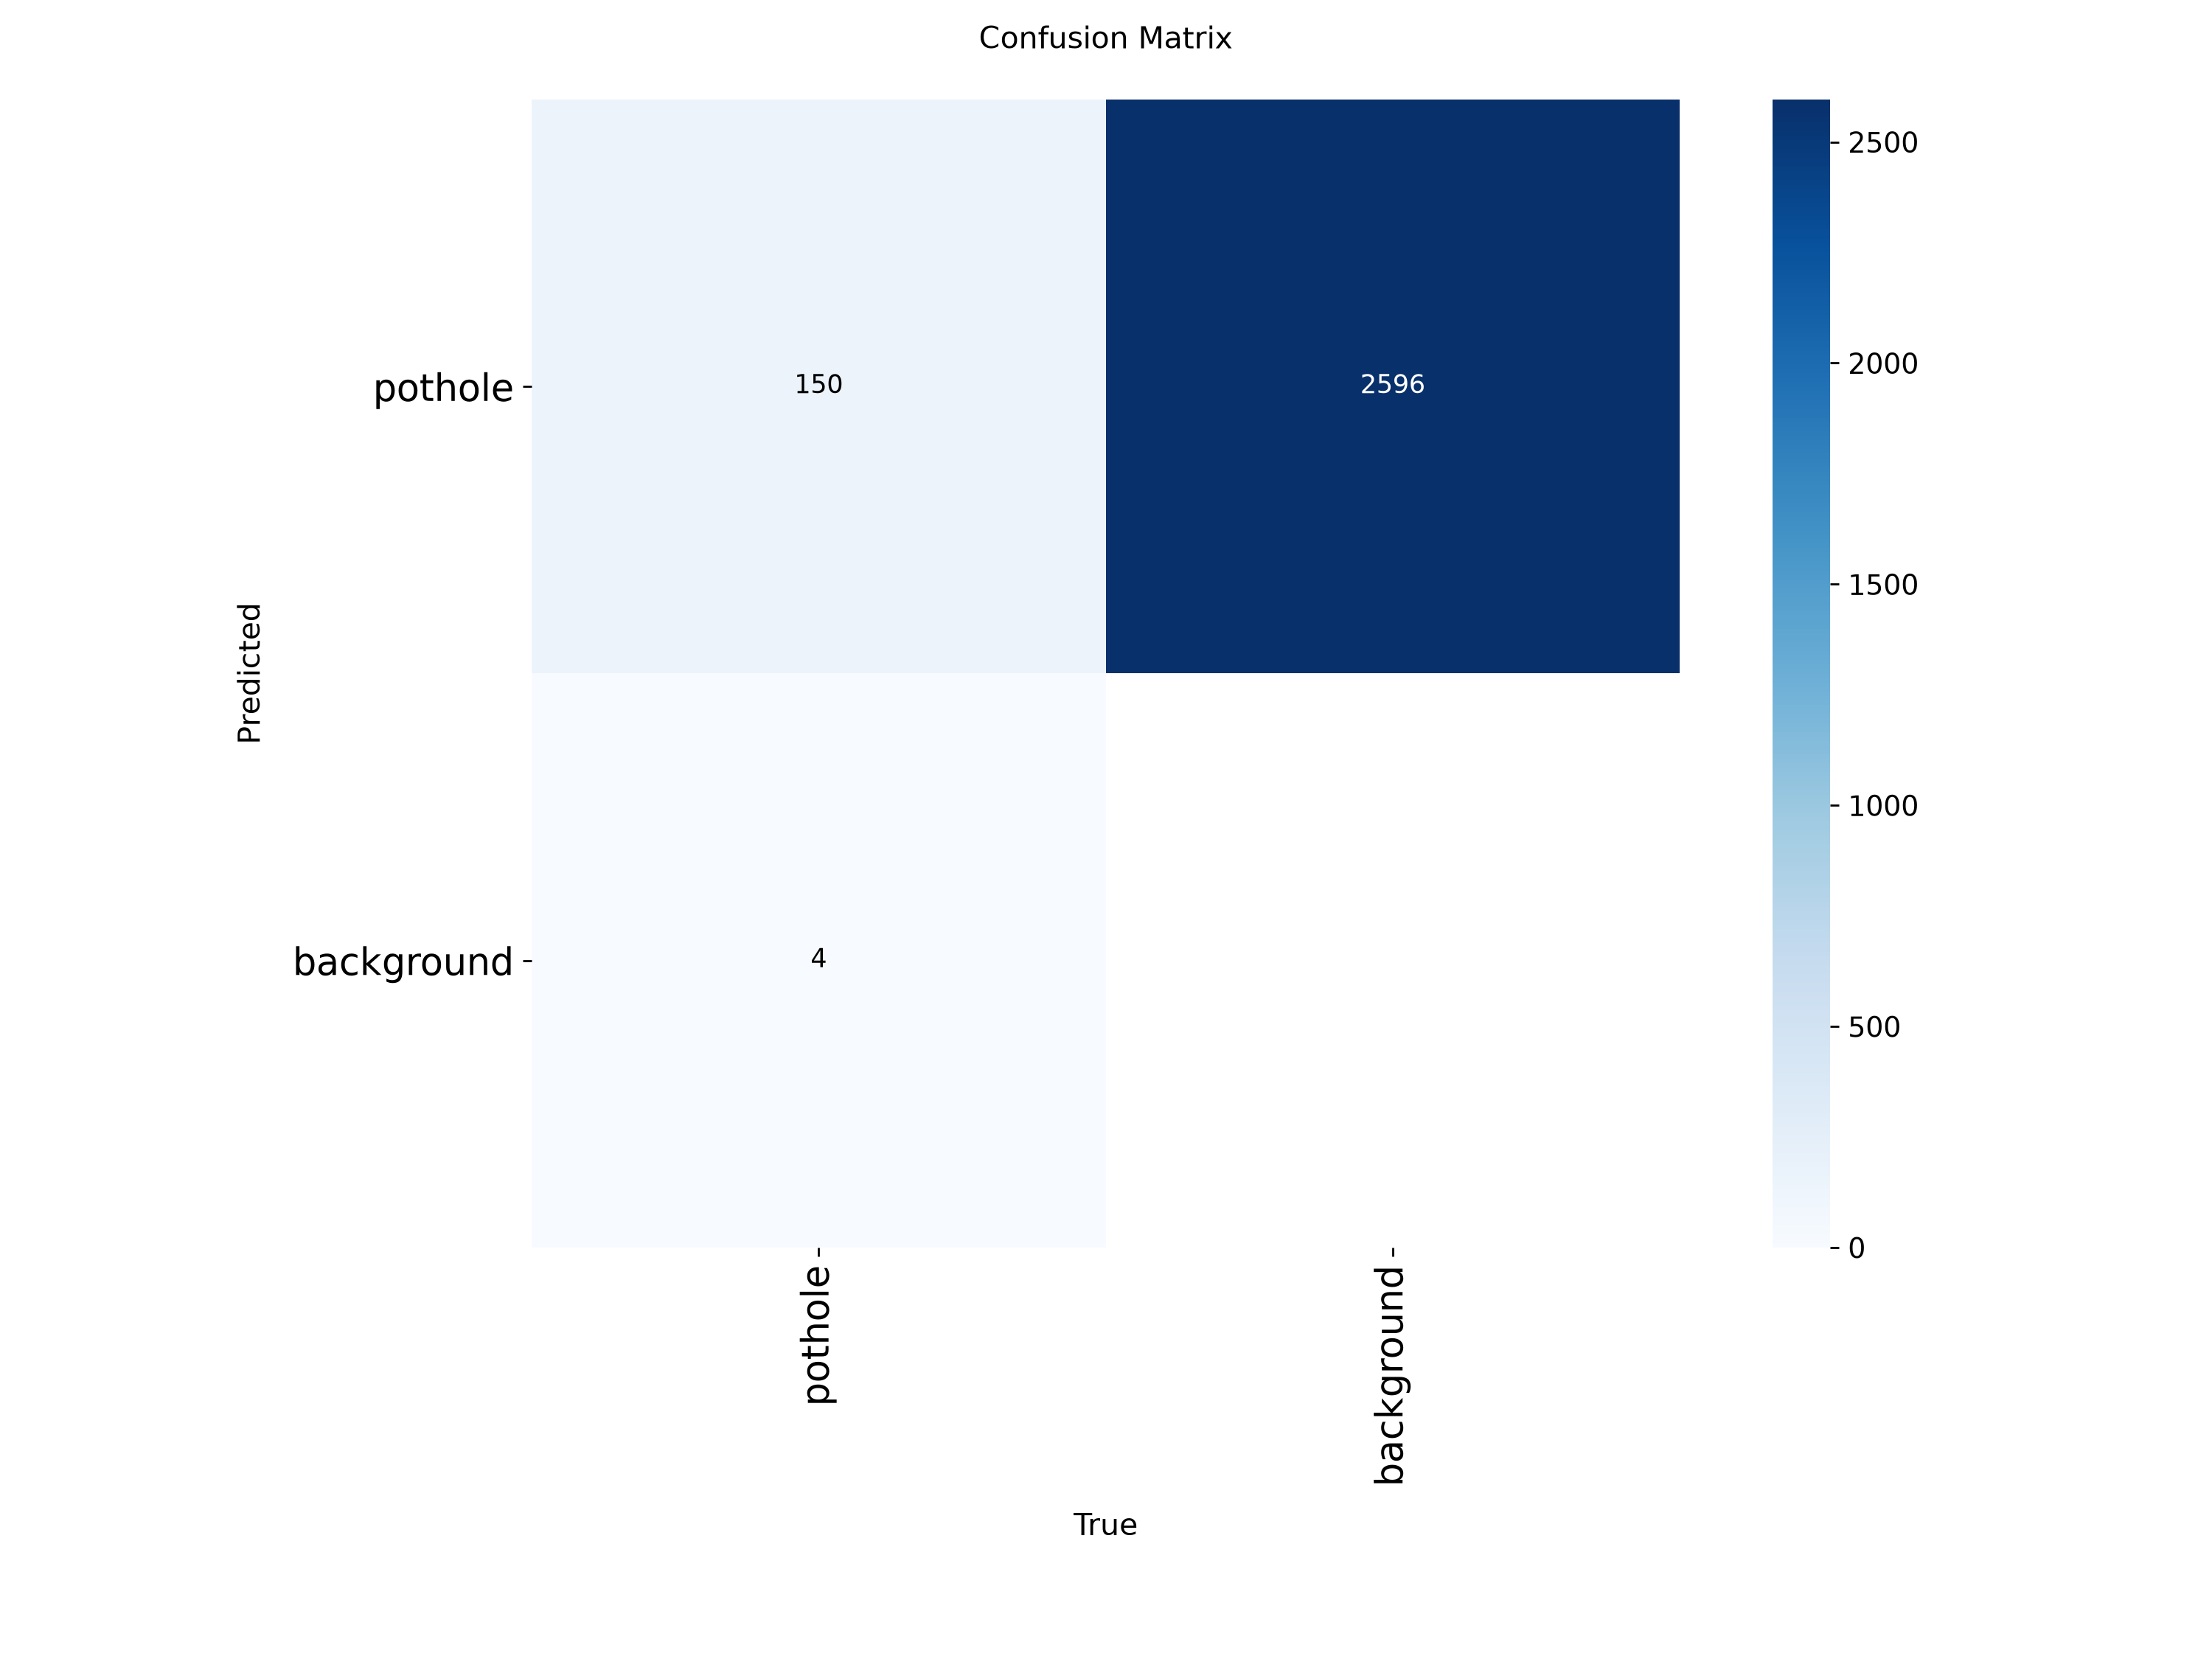

confusion_matrix_normalized.png


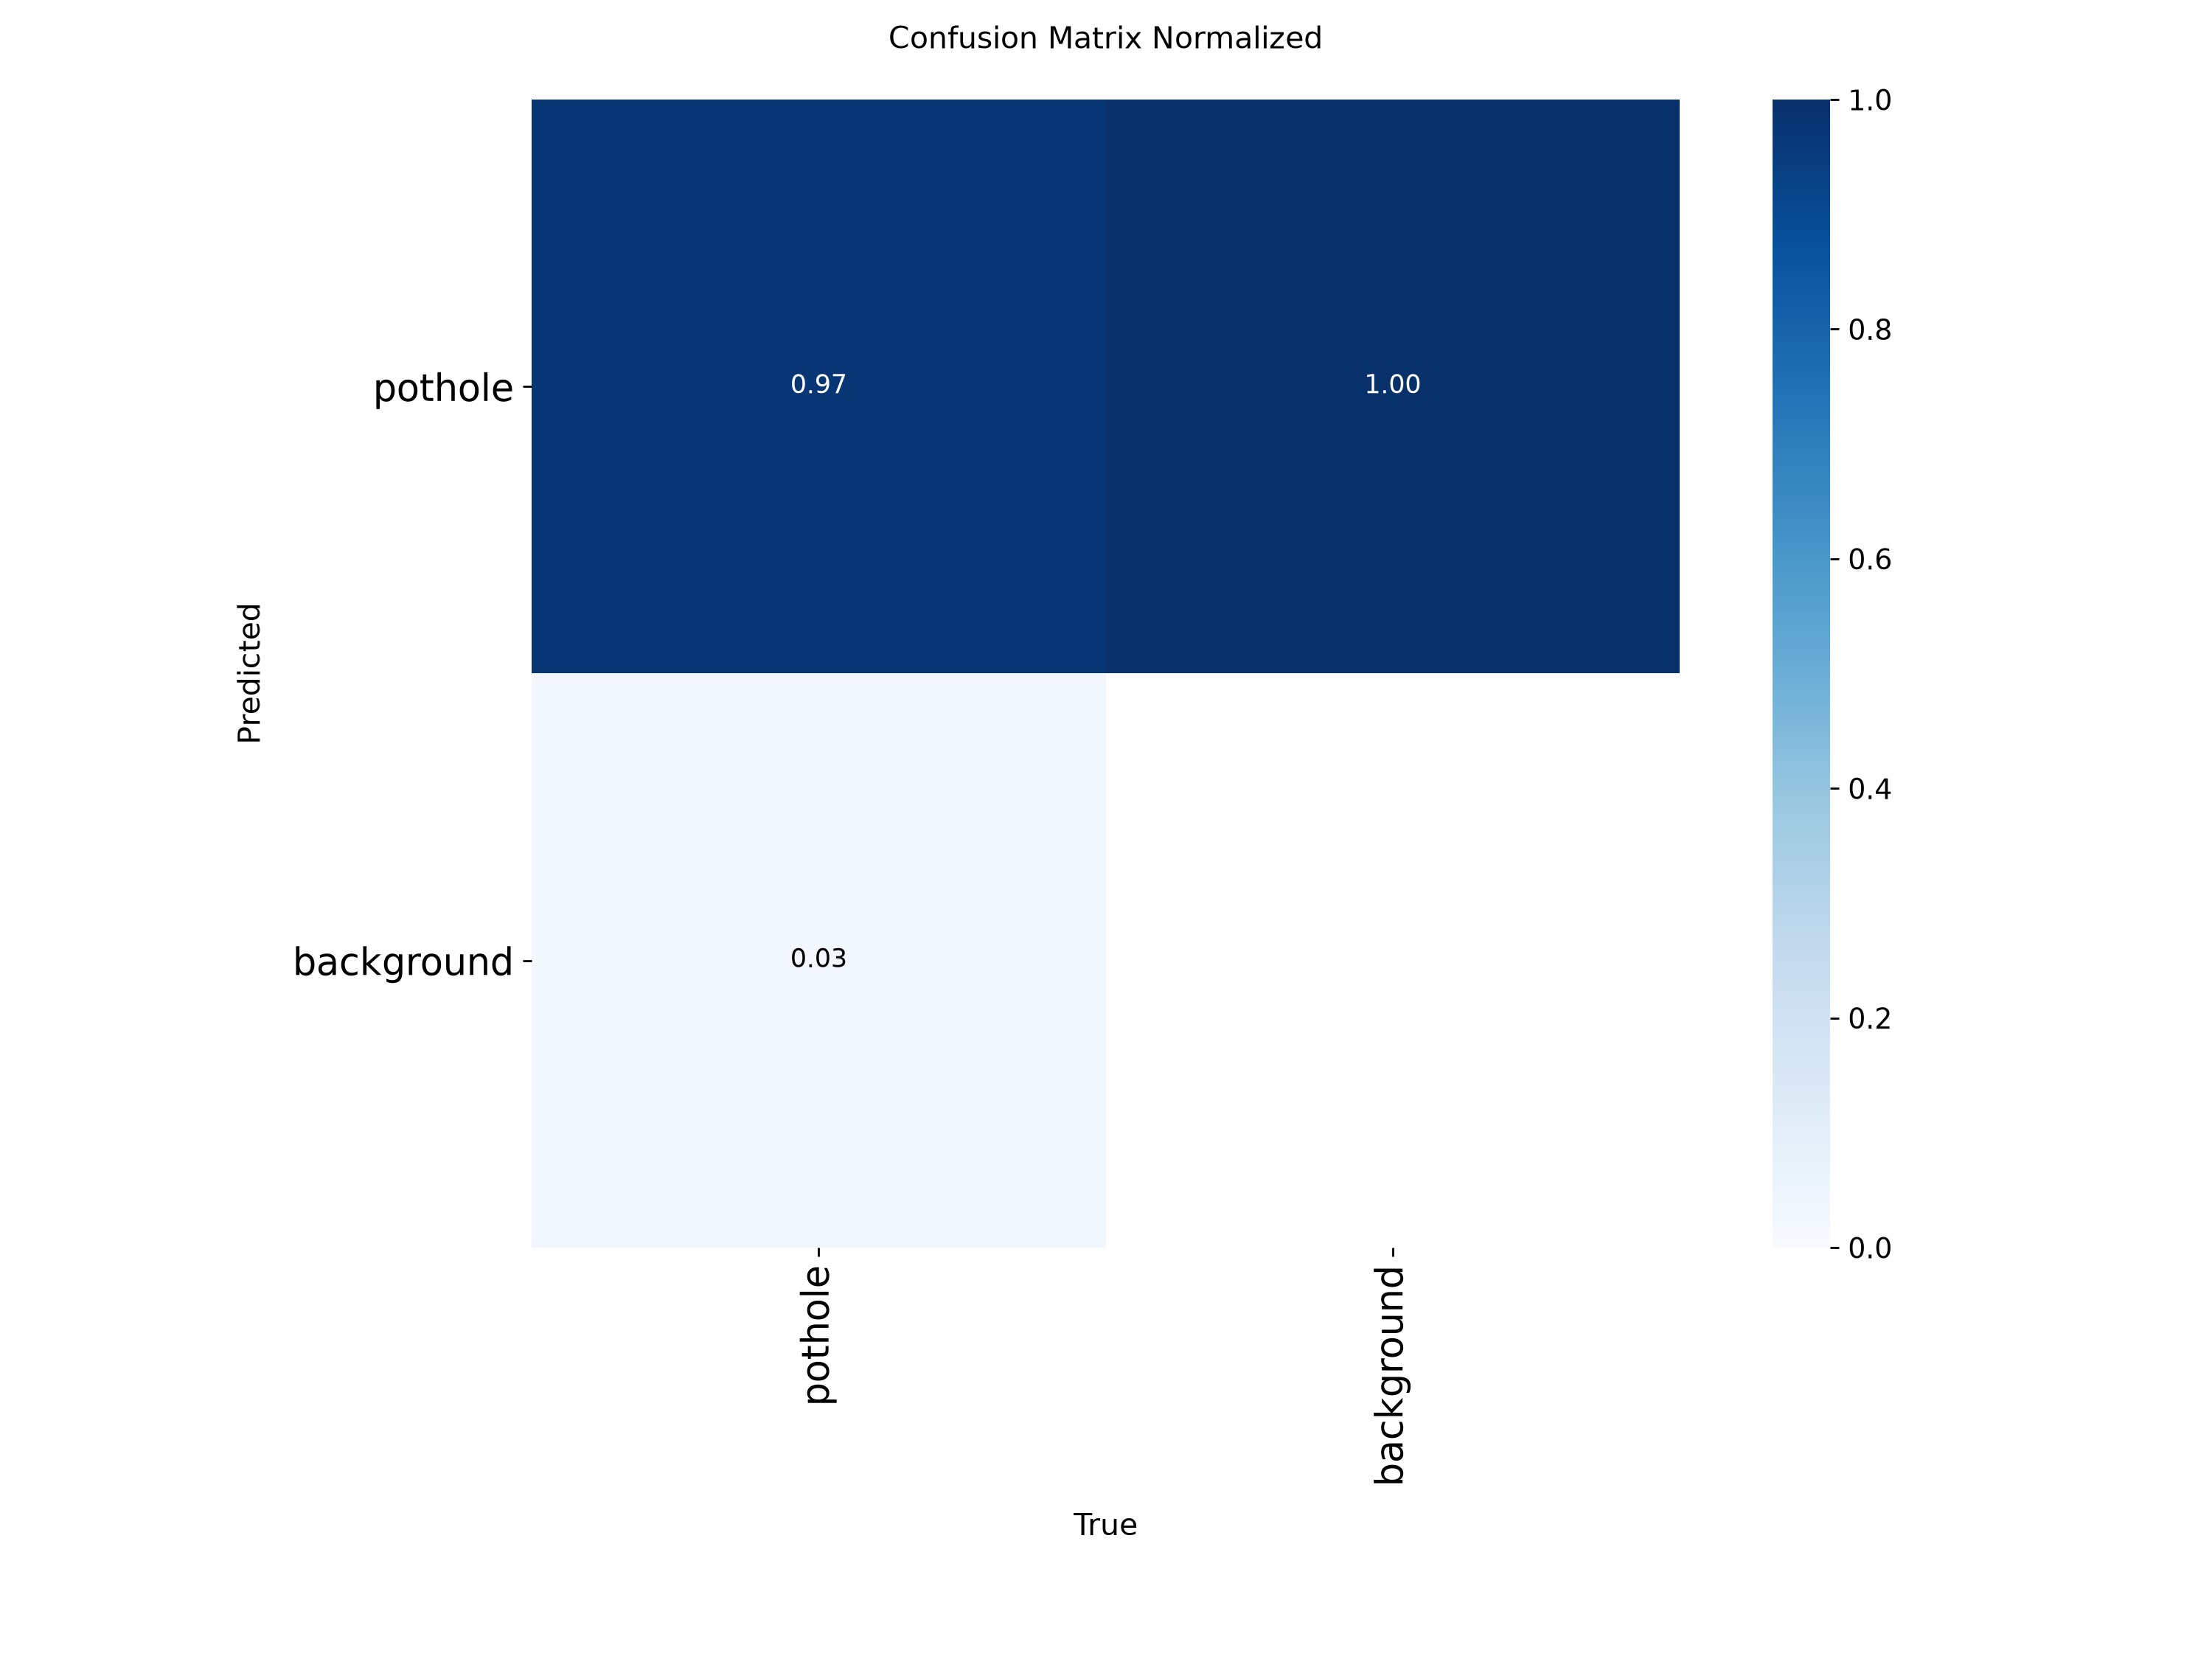

In [9]:
from pathlib import Path
import pandas as pd
from PIL import Image
from IPython.display import display

project_dir = Path.home() / "RoadDamageDetection"

analysis_dir = (
    project_dir / "results" / "yolov8n_test_analysis"
)

print("Evaluation files:")
for path in sorted(analysis_dir.iterdir()):
    if path.is_file():
        print(path.name)

print("\nTraining history:")
history_path = (
    project_dir / "results"
    / "yolov8n_baseline" / "results.csv"
)

if history_path.exists():
    history = pd.read_csv(history_path)
    print("Rows:", len(history))
    display(history.tail(5))

print("\nAvailable confusion matrix images:")
for filename in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
]:
    path = analysis_dir / filename
    if path.exists():
        print(filename)
        display(Image.open(path))

BoxPR_curve.png


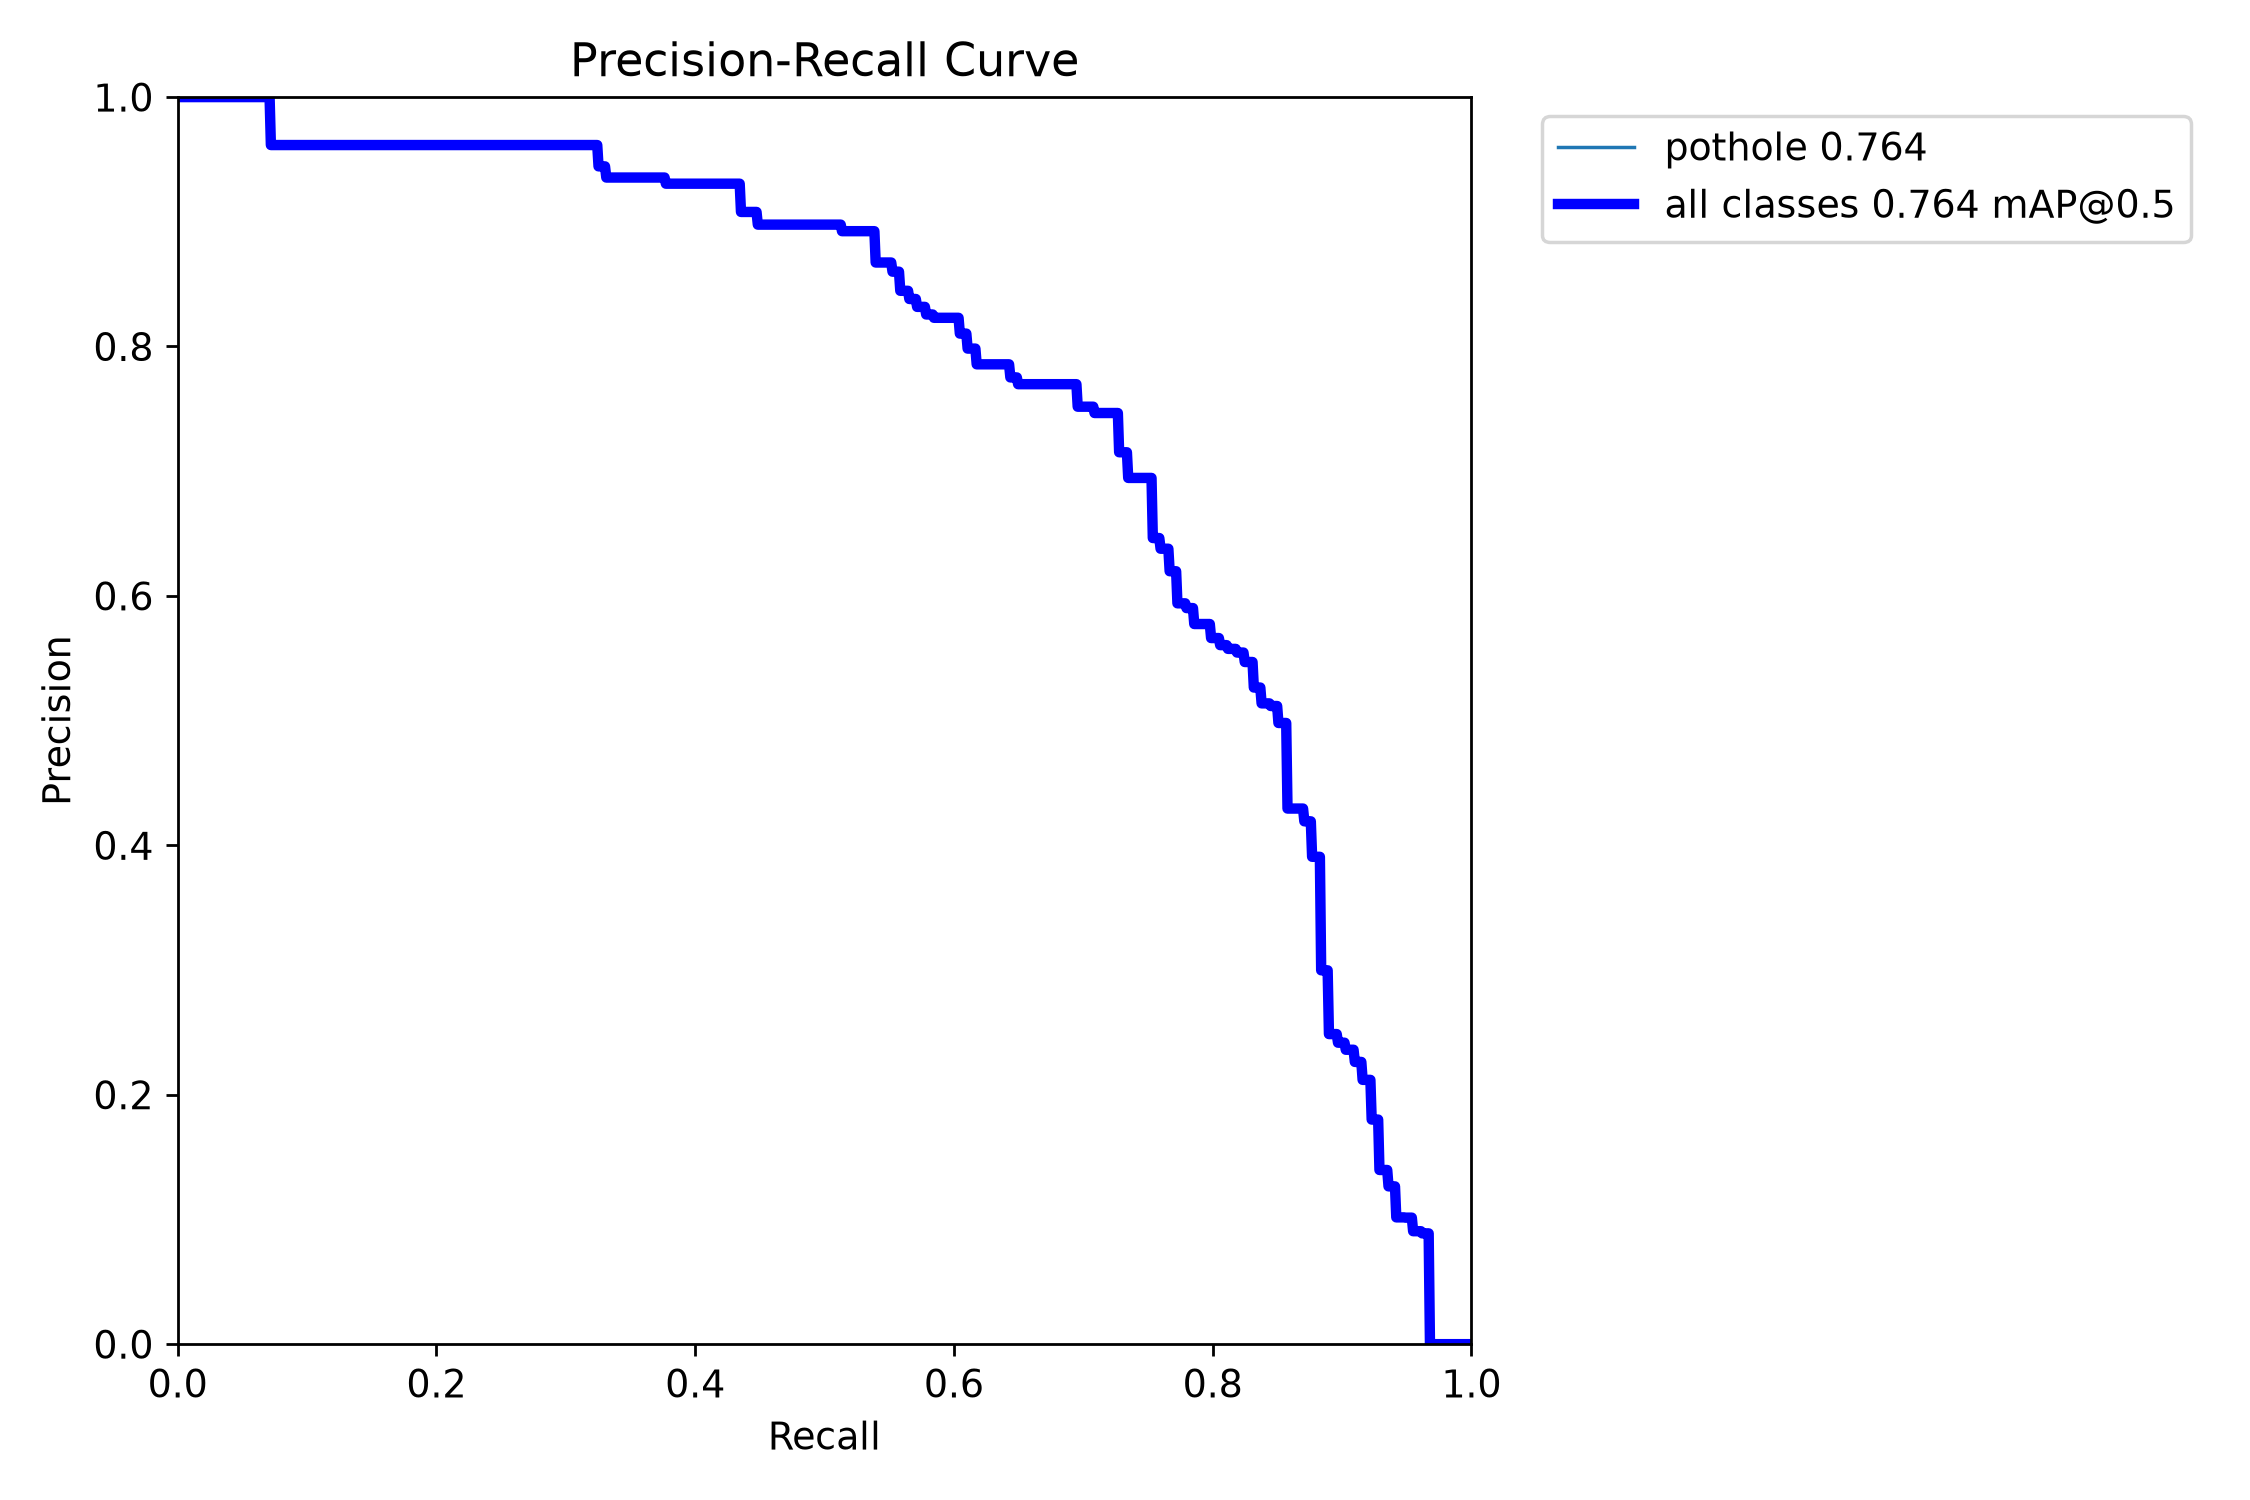

BoxF1_curve.png


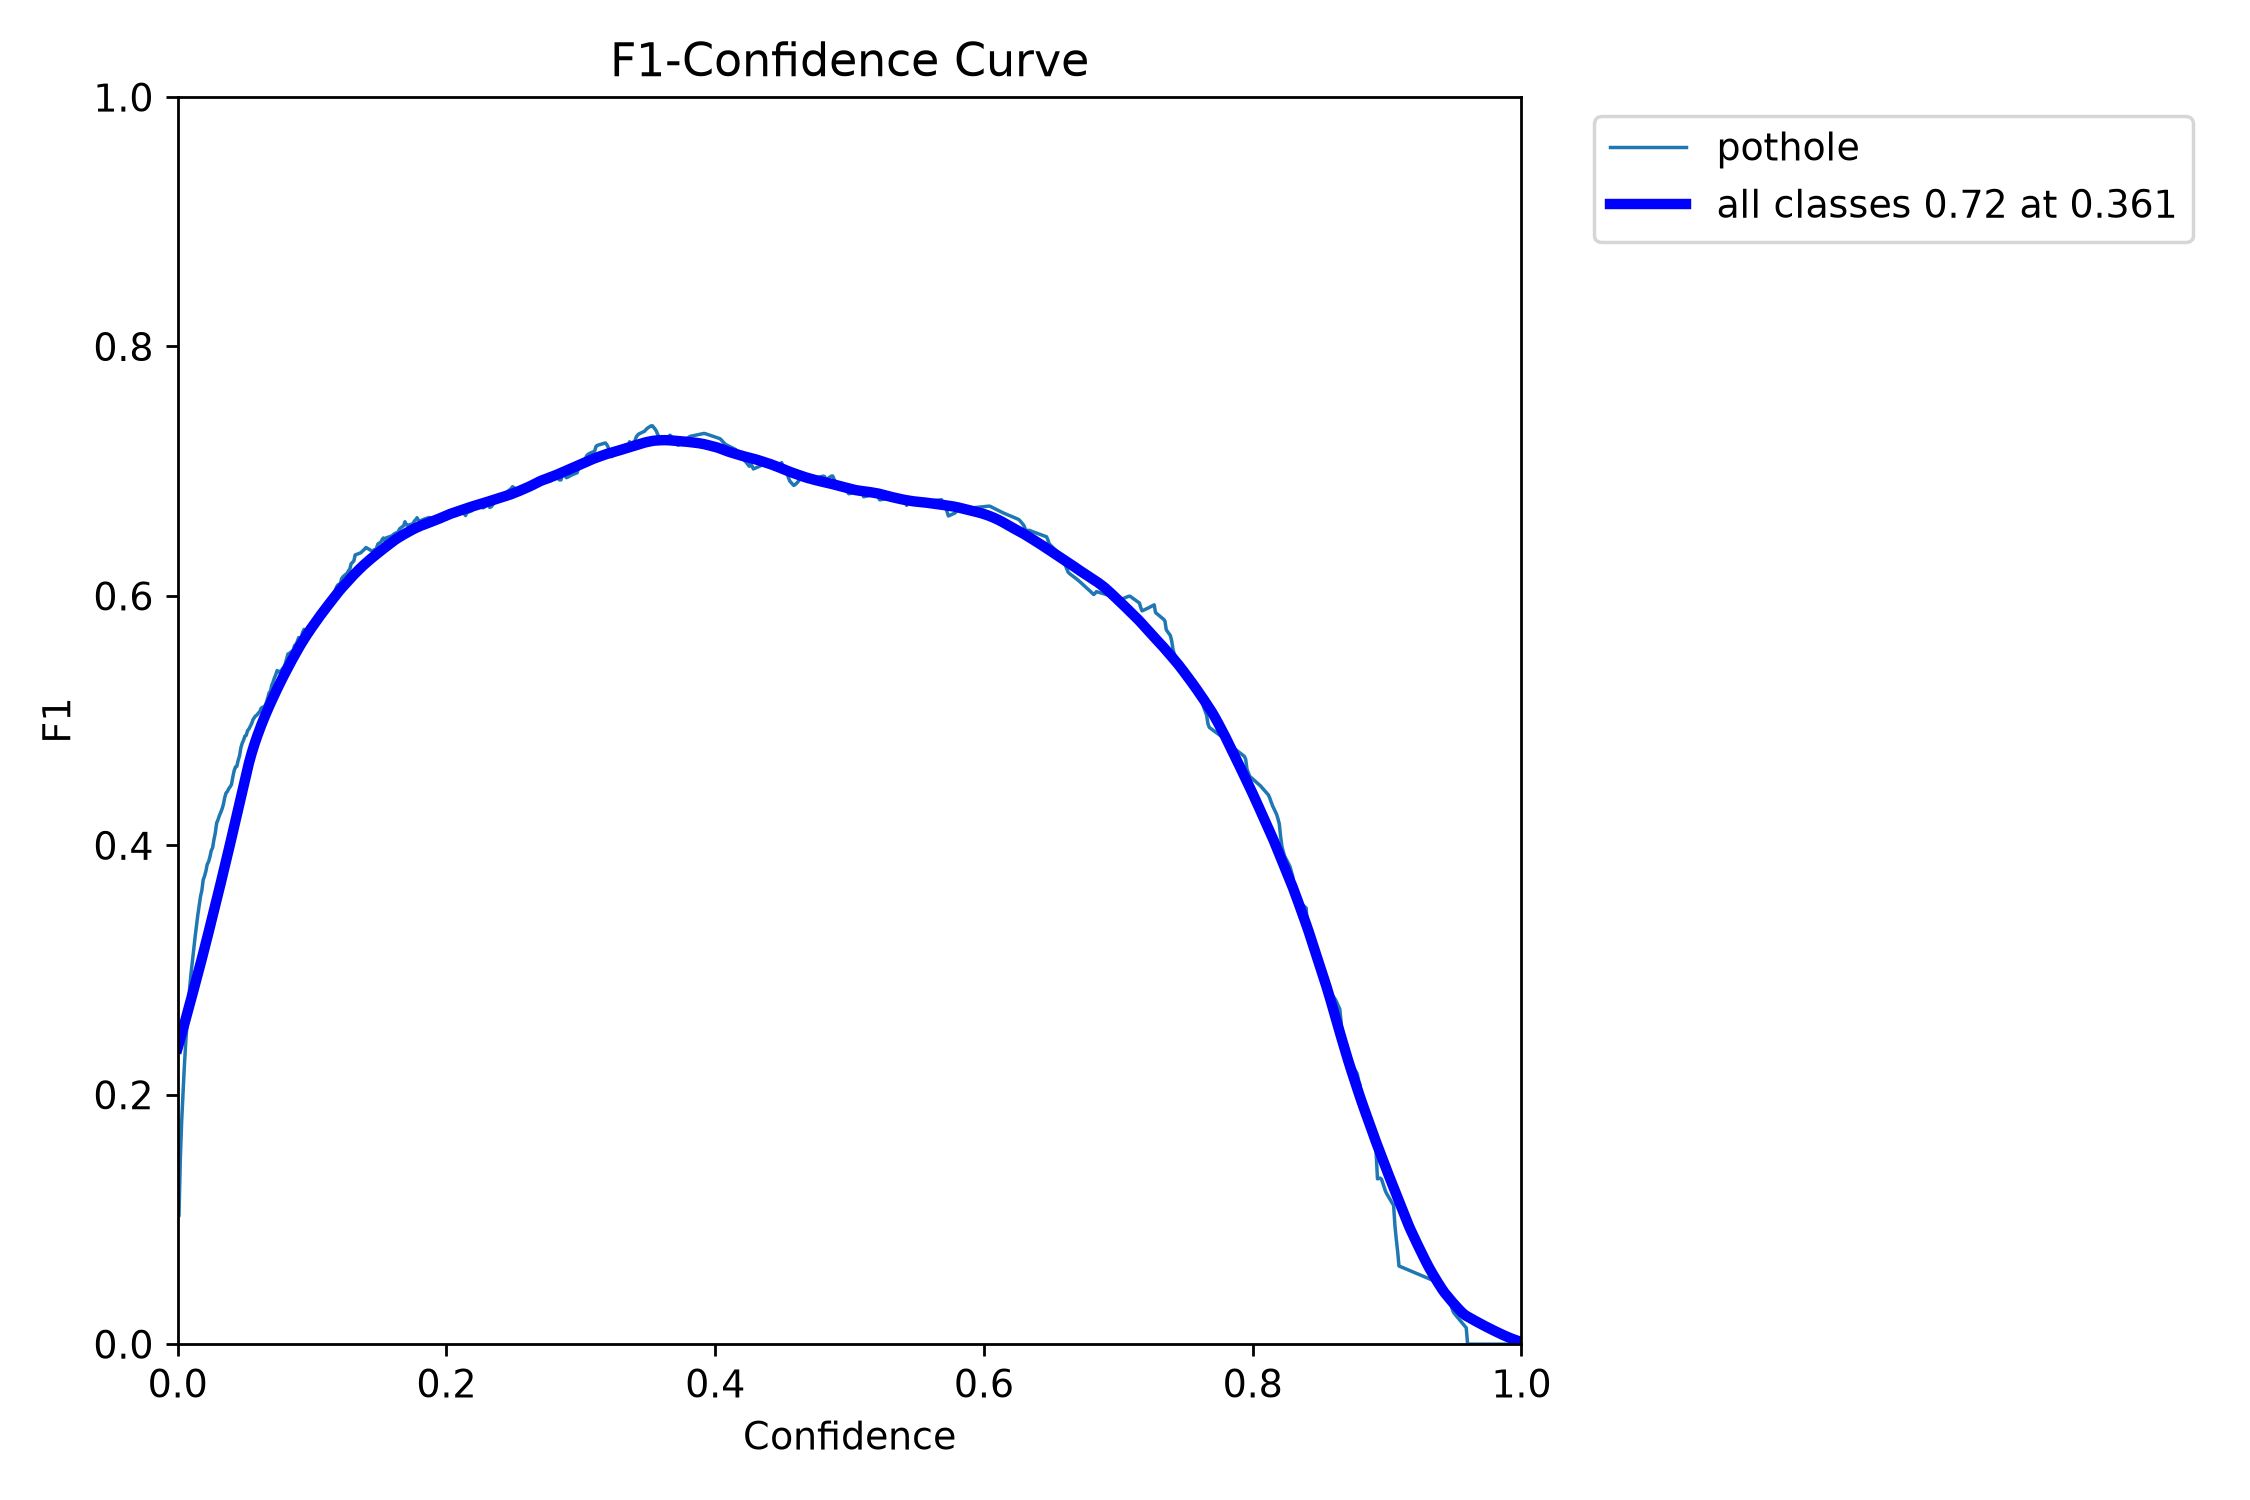

BoxP_curve.png


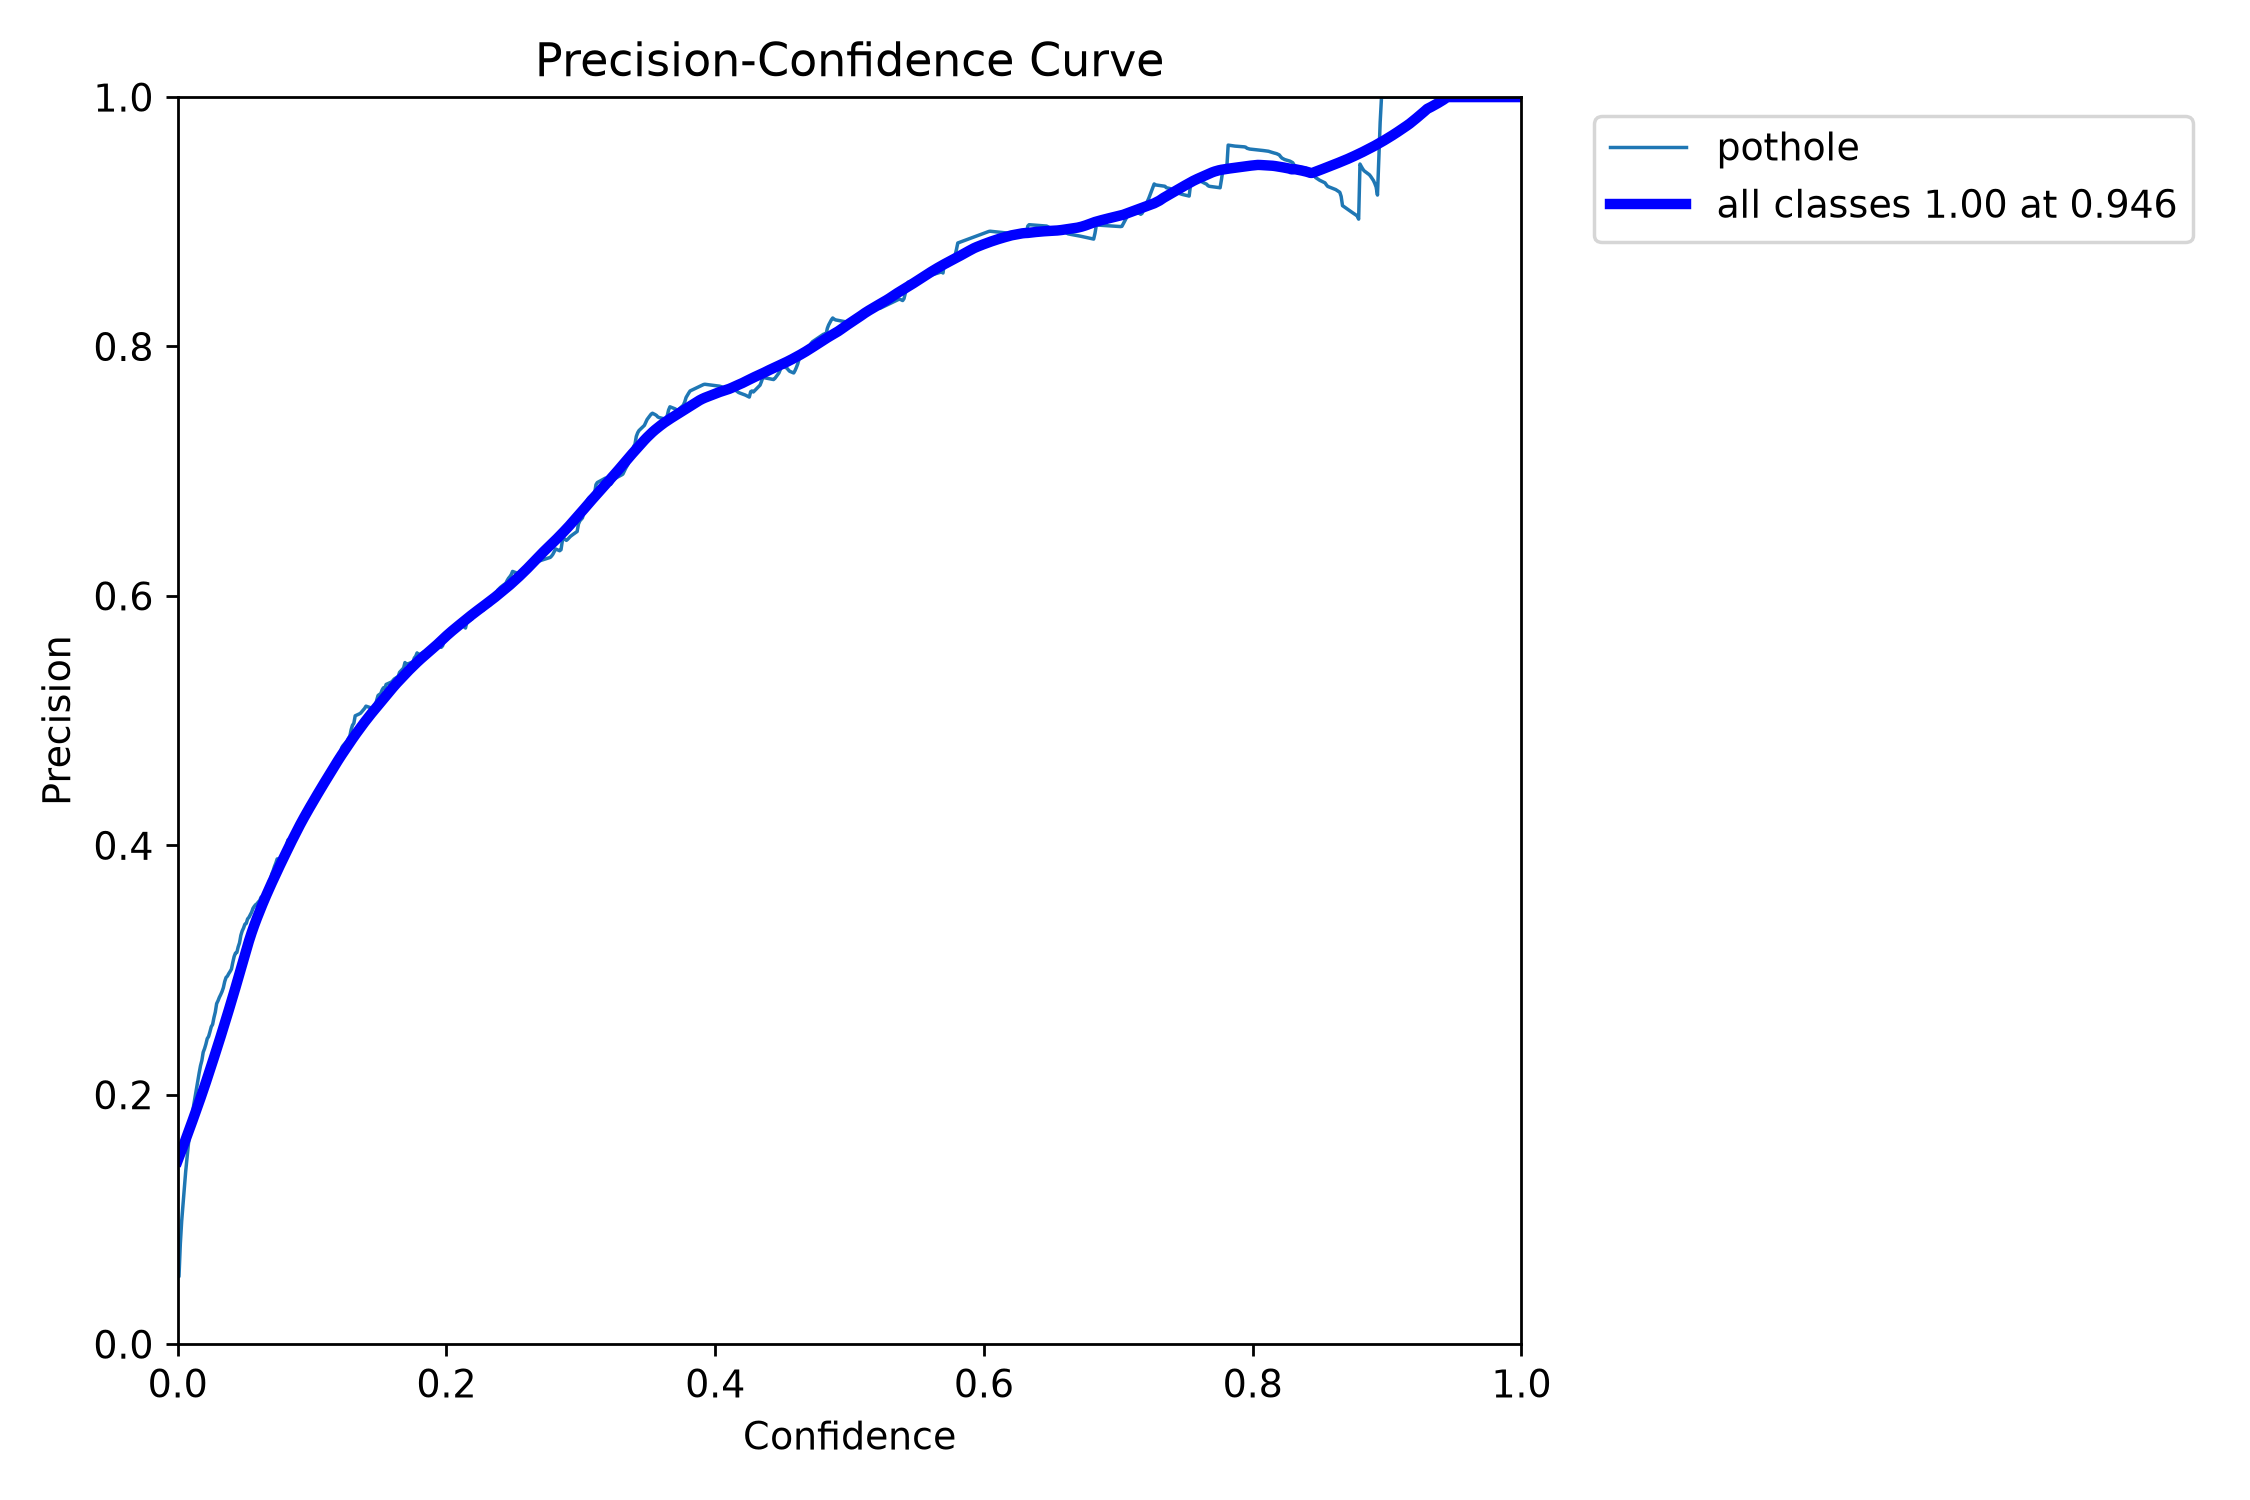

BoxR_curve.png


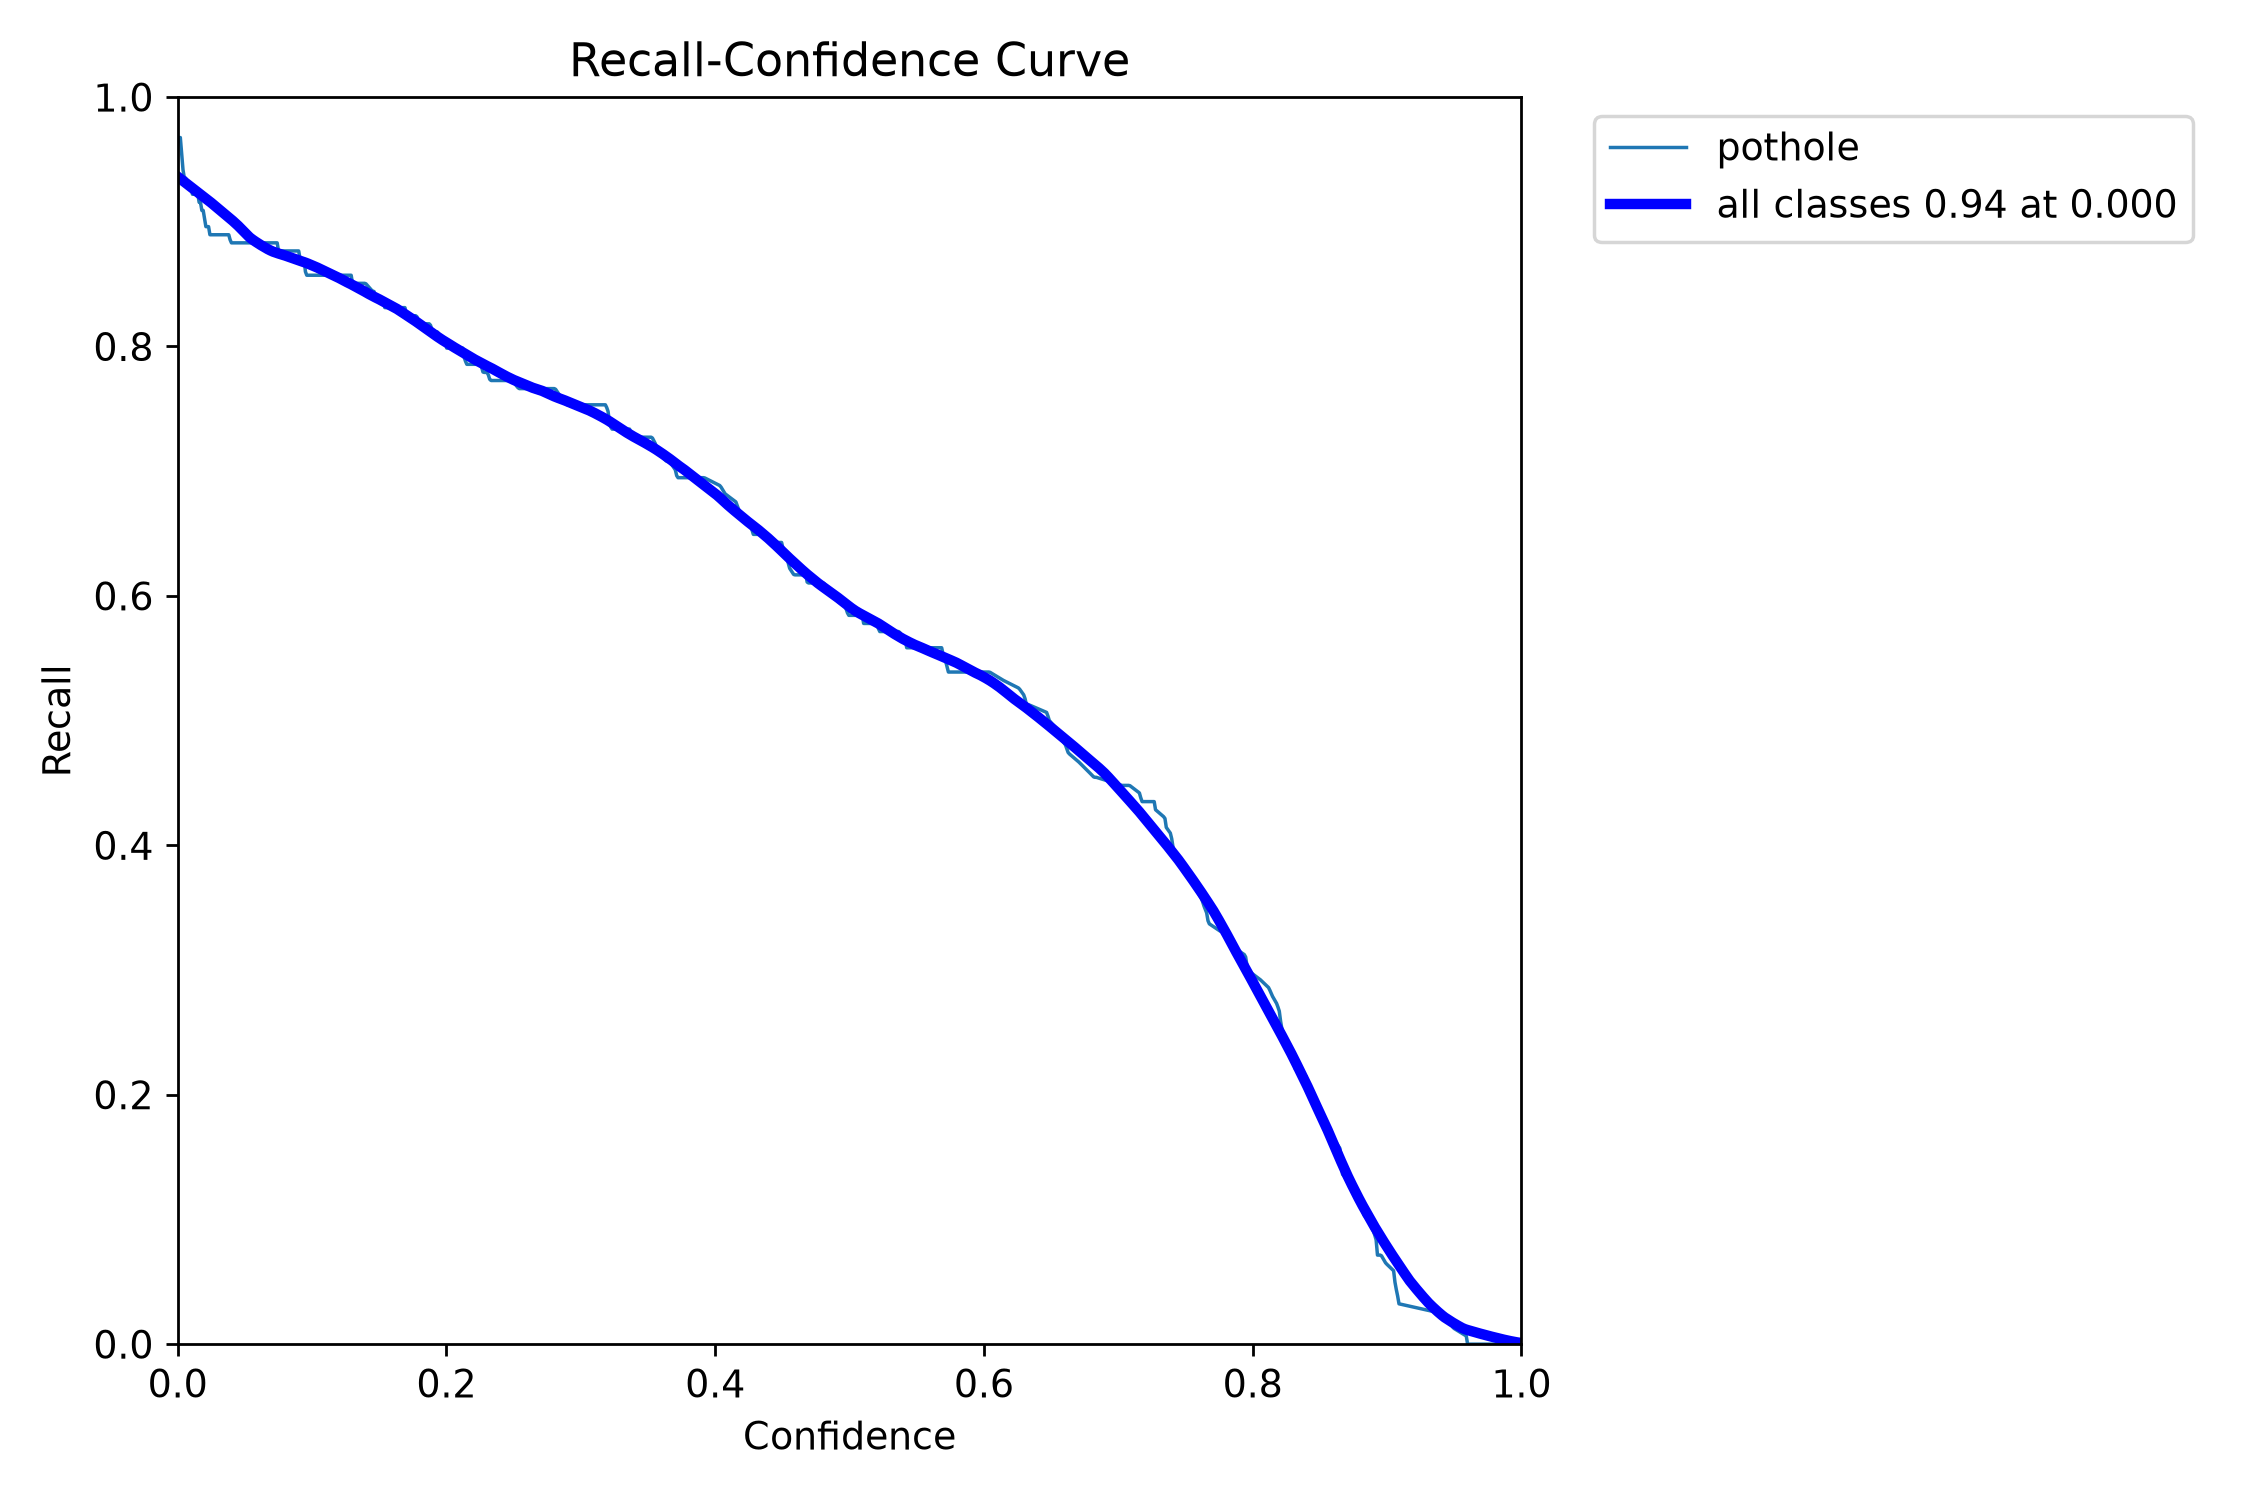

In [10]:
from pathlib import Path
from PIL import Image
from IPython.display import display

project_dir = Path.home() / "RoadDamageDetection"

analysis_dir = (
    project_dir
    / "results"
    / "yolov8n_test_analysis"
)

curve_files = [
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
]

for filename in curve_files:
    path = analysis_dir / filename

    if path.exists():
        print(filename)
        display(Image.open(path))
    else:
        print("Not found:", filename)

## 8. Cleaned-Test Evaluation

A separate copy of the test labels is used to exclude the malformed zero-width annotation without changing the original dataset. The cleaned test set has 67 images and 153 valid ground-truth boxes. The missing ground-truth box has not been reconstructed, so the cleaned metrics must be interpreted with that limitation.

In [11]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"

original_dir = project_dir / "data" / "test" / "labels"
clean_dir = project_dir / "data" / "test_labels_clean"

def count_valid_boxes(label_dir):
    valid_count = 0
    invalid_count = 0

    for file in label_dir.glob("*.txt"):
        for line in file.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue

            parts = line.split()

            try:
                values = [float(x) for x in parts]

                valid = (
                    len(values) == 5
                    and values[0] == 0
                    and all(0 <= x <= 1 for x in values[1:])
                    and values[3] > 0
                    and values[4] > 0
                )

            except ValueError:
                valid = False

            if valid:
                valid_count += 1
            else:
                invalid_count += 1

    return valid_count, invalid_count

original_valid, original_invalid = count_valid_boxes(original_dir)
clean_valid, clean_invalid = count_valid_boxes(clean_dir)

print("ORIGINAL TEST LABELS")
print("Valid boxes:", original_valid)
print("Invalid lines:", original_invalid)

print("\nCLEANED TEST LABEL COPY")
print("Valid boxes:", clean_valid)
print("Invalid lines:", clean_invalid)

ORIGINAL TEST LABELS
Valid boxes: 153
Invalid lines: 1

CLEANED TEST LABEL COPY
Valid boxes: 153
Invalid lines: 0


In [12]:
from pathlib import Path
import yaml

project_dir = Path.home() / "RoadDamageDetection"
data_dir = project_dir / "data"

clean_config = {
    "path": str(data_dir.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test_clean/images",
    "nc": 1,
    "names": ["pothole"],
}

clean_config_path = data_dir / "data_yolov8_clean_test.yaml"

with open(clean_config_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(clean_config, f, sort_keys=False)

print("Clean-test configuration created:")
print(clean_config_path)
print("\nConfiguration contents:")
print(clean_config_path.read_text(encoding="utf-8"))

Clean-test configuration created:
C:\Users\thesh\RoadDamageDetection\data\data_yolov8_clean_test.yaml

Configuration contents:
path: C:\Users\thesh\RoadDamageDetection\data
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- pothole



In [13]:
from pathlib import Path
import shutil
import yaml

project_dir = Path.home() / "RoadDamageDetection"
data_dir = project_dir / "data"


test_images = data_dir / "test" / "images"
clean_labels = data_dir / "test_labels_clean"


clean_test_dir = data_dir / "test_clean"
clean_test_images = clean_test_dir / "images"
clean_test_labels = clean_test_dir / "labels"

assert test_images.exists(), "Original test images folder not found."
assert clean_labels.exists(), "Cleaned test labels folder not found."


clean_test_images.mkdir(parents=True, exist_ok=True)
clean_test_labels.mkdir(parents=True, exist_ok=True)


for image_file in test_images.iterdir():
    if image_file.is_file():
        shutil.copy2(image_file, clean_test_images / image_file.name)


for label_file in clean_labels.glob("*.txt"):
    shutil.copy2(label_file, clean_test_labels / label_file.name)


config = {
    "path": str(data_dir.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test_clean/images",
    "nc": 1,
    "names": ["pothole"],
}

config_path = data_dir / "data_yolov8_clean_test.yaml"

with open(config_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)


image_count = sum(
    1 for p in clean_test_images.iterdir()
    if p.is_file()
)

label_count = len(list(clean_test_labels.glob("*.txt")))

print("Clean test dataset prepared.")
print("Images:", image_count)
print("Label files:", label_count)
print("Configuration:", config_path)
print("Original dataset preserved:", test_images.exists())

Clean test dataset prepared.
Images: 67
Label files: 67
Configuration: C:\Users\thesh\RoadDamageDetection\data\data_yolov8_clean_test.yaml
Original dataset preserved: True


### 8.1 Evaluate the saved model on the cleaned test split

This cell evaluates the existing `best.pt` checkpoint against `test_clean/images` and its matching cleaned labels. It does not retrain the model.

In [14]:
from pathlib import Path
from ultralytics import YOLO

project_dir = Path.home() / "RoadDamageDetection"

model_path = (
    project_dir
    / "results"
    / "yolov8n_baseline"
    / "weights"
    / "best.pt"
)

data_yaml = (
    project_dir
    / "data"
    / "data_yolov8_clean_test.yaml"
)

assert model_path.exists(), f"Model not found: {model_path}"
assert data_yaml.exists(), f"Dataset configuration not found: {data_yaml}"

model = YOLO(str(model_path))

results = model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    workers=0,
    plots=True,
    project=str(project_dir / "results"),
    name="yolov8n_clean_test_evaluation",
    exist_ok=True
)

print("\nCLEAN TEST EVALUATION RESULTS")
print("Precision:", round(float(results.box.mp), 4))
print("Recall:", round(float(results.box.mr), 4))
print("mAP@0.5:", round(float(results.box.map50), 4))
print("mAP@0.5:0.95:", round(float(results.box.map), 4))

print("\nResults saved to:")
print(
    project_dir
    / "results"
    / "yolov8n_clean_test_evaluation"
)

Ultralytics 8.4.190  Python-3.11.17 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 8.3±6.7 MB/s, size: 57.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\thesh\RoadDamageDetection\data\test_clean\labels... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 705.5it/s 0.1s
val: New cache created: C:\Users\thesh\RoadDamageDetection\data\test_clean\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 12.8it/s 1.3s0.1s
                   all         67        153      0.742      0.715      0.769      0.501
Speed: 0.6ms preprocess, 9.1ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to C:\Users\thesh\RoadDamageDetectio

### 8.2 Verify the cleaned test labels

This check confirms image/label pairing and validates the format and dimensions of every non-empty annotation row.

In [15]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"

image_dir = project_dir / "data" / "test_clean" / "images"
label_dir = project_dir / "data" / "test_clean" / "labels"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = {
    p.stem for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
}

labels = {p.stem for p in label_dir.glob("*.txt")}

missing_labels = sorted(images - labels)
orphan_labels = sorted(labels - images)

invalid_lines = []

for label_file in label_dir.glob("*.txt"):
    for line_number, line in enumerate(
        label_file.read_text(encoding="utf-8").splitlines(), start=1
    ):
        if not line.strip():
            continue

        try:
            parts = line.split()
            values = [float(x) for x in parts]

            valid = (
                len(values) == 5
                and values[0] == 0
                and all(0 <= x <= 1 for x in values[1:])
                and values[3] > 0
                and values[4] > 0
            )
        except ValueError:
            valid = False

        if not valid:
            invalid_lines.append(
                (label_file.name, line_number, line)
            )

print("Clean test images:", len(images))
print("Clean test label files:", len(labels))
print("Images missing labels:", len(missing_labels))
print("Labels without matching images:", len(orphan_labels))
print("Invalid annotation lines:", len(invalid_lines))

if missing_labels:
    print("\nMissing labels:", missing_labels)

if orphan_labels:
    print("\nOrphan labels:", orphan_labels)

if invalid_lines:
    print("\nInvalid lines:", invalid_lines[:10])

Clean test images: 67
Clean test label files: 67
Images missing labels: 0
Labels without matching images: 0
Invalid annotation lines: 0


## 9. Record the Evaluation Summary

The summary JSON stores the cleaned-test metrics and documents the annotation limitation. These values are rounded summaries of the evaluation output; retain the original Ultralytics output folder and plots as the detailed record.

In [16]:
from pathlib import Path
import json
from datetime import datetime

project_dir = Path.home() / "RoadDamageDetection"

summary = {
    "project": "Road Damage and Pothole Detection",
    "model": "YOLOv8 Nano",
    "hardware": "NVIDIA GeForce RTX 2050, 4 GB VRAM",
    "training_epochs": 30,
    "test_images": 67,
    "cleaned_test_ground_truth_instances": 153,
    "evaluation": {
        "precision": 0.7422,
        "recall": 0.7151,
        "mAP50": 0.7688,
        "mAP50_95": 0.5006
    },
    "model_path": "results/yolov8n_baseline/weights/best.pt",
    "application_path": "app.py",
    "evaluation_path": "results/yolov8n_clean_test_evaluation",
    "notes": [
        "Results are from the cleaned test-label copy.",
        "One malformed zero-width annotation was excluded.",
        "The missing ground-truth box was not reconstructed.",
        "Results should be interpreted with this data-quality limitation.",
        "The model is a research prototype and is not validated for operational road-safety decisions."
    ]
}

summary_path = project_dir / "final_evaluation_summary.json"

summary_path.write_text(
    json.dumps(summary, indent=4),
    encoding="utf-8"
)

print("Final evaluation summary saved:")
print(summary_path)
print("\nReported metrics:")
for metric, value in summary["evaluation"].items():
    print(f"{metric}: {value:.4f}")

Final evaluation summary saved:
C:\Users\thesh\RoadDamageDetection\final_evaluation_summary.json

Reported metrics:
precision: 0.7422
recall: 0.7151
mAP50: 0.7688
mAP50_95: 0.5006


In [17]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"

expected_files = [
    "app.py",
    "data/data.yaml",
    "data/data_yolov8.yaml",
    "data/data_yolov8_clean_test.yaml",
    "results/yolov8n_baseline/weights/best.pt",
    "results/yolov8n_baseline/weights/last.pt",
    "results/yolov8n_baseline/results.csv",
    "results/yolov8n_clean_test_evaluation/confusion_matrix.png",
    "final_evaluation_summary.json",
]

print("FINAL PROJECT FILE CHECK\n")

for relative_path in expected_files:
    path = project_dir / relative_path
    print(f"{'OK' if path.exists() else 'NOT FOUND'}  {relative_path}")

print("\nProject directory:", project_dir)

FINAL PROJECT FILE CHECK

OK  app.py
OK  data/data.yaml
OK  data/data_yolov8.yaml
OK  data/data_yolov8_clean_test.yaml
OK  results/yolov8n_baseline/weights/best.pt
OK  results/yolov8n_baseline/weights/last.pt
OK  results/yolov8n_baseline/results.csv
NOT FOUND  results/yolov8_clean_test_evaluation/results.csv
OK  final_evaluation_summary.json

Project directory: C:\Users\thesh\RoadDamageDetection


In [18]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"

folders = [
    project_dir / "results" / "yolov8n_clean_test_evaluation",
    project_dir / "results" / "yolov8n_test_analysis",
]

for folder in folders:
    print(f"\nFolder: {folder}")
    print("Exists:", folder.exists())

    if folder.exists():
        for path in sorted(folder.iterdir()):
            print(" ", path.name)


Folder: C:\Users\thesh\RoadDamageDetection\results\yolov8n_clean_test_evaluation
Exists: True
  BoxF1_curve.png
  BoxP_curve.png
  BoxPR_curve.png
  BoxR_curve.png
  confusion_matrix.png
  confusion_matrix_normalized.png
  val_batch0_labels.jpg
  val_batch0_pred.jpg
  val_batch1_labels.jpg
  val_batch1_pred.jpg
  val_batch2_labels.jpg
  val_batch2_pred.jpg

Folder: C:\Users\thesh\RoadDamageDetection\results\yolov8n_test_analysis
Exists: True
  BoxF1_curve.png
  BoxP_curve.png
  BoxPR_curve.png
  BoxR_curve.png
  confusion_matrix.png
  confusion_matrix_normalized.png
  val_batch0_labels.jpg
  val_batch0_pred.jpg
  val_batch1_labels.jpg
  val_batch1_pred.jpg
  val_batch2_labels.jpg
  val_batch2_pred.jpg


In [19]:
from pathlib import Path

project_dir = Path.home() / "RoadDamageDetection"

print("PROJECT NOTEBOOKS\n")

notebooks = list(project_dir.glob("*.ipynb"))

if notebooks:
    for notebook in notebooks:
        print("Found:", notebook.name)
        print("Size:", round(notebook.stat().st_size / 1024, 2), "KB")
else:
    print("No notebook found directly in the project folder.")

print("\nPROJECT ARTIFACTS")

for relative_path in [
    "app.py",
    "final_evaluation_summary.json",
    "results/yolov8n_baseline/weights/best.pt",
    "results/yolov8n_baseline/results.csv",
    "results/yolov8n_clean_test_evaluation/confusion_matrix.png",
]:
    path = project_dir / relative_path
    print(f"{'OK' if path.exists() else 'MISSING'}: {relative_path}")

PROJECT NOTEBOOKS

Found: 02_Road_Damage_Pothole_Detection.ipynb
Size: 2630.51 KB

PROJECT ARTIFACTS
OK: app.py
OK: final_evaluation_summary.json
OK: results/yolov8n_baseline/weights/best.pt
OK: results/yolov8n_baseline/results.csv
OK: results/yolov8n_clean_test_evaluation/confusion_matrix.png


## 10. Conclusion, Limitations, and Future Work

### Conclusion
A YOLOv8 Nano baseline was trained for 30 epochs, evaluated, and integrated into a working Streamlit prototype for image-based pothole detection.

### Reported cleaned-test metrics
- Precision: 74.22%
- Recall: 71.51%
- mAP@0.5: 76.88%
- mAP@0.5:0.95: 50.06%

### Limitations
- The test split contains 67 images, so results may not generalize to varied roads, lighting, weather, and camera viewpoints.
- One malformed zero-width annotation was excluded from the cleaned-label copy; its missing ground-truth box was not reconstructed.
- Confidence scores are not guarantees of correctness, and visual examples showed possible false-positive detections.
- The cleaned-test results are diagnostic and should not be presented as an untouched independent benchmark because the test split was inspected repeatedly during development.
- The application is a prototype for research and demonstration, not a validated road-safety decision system.

### Future work
- Review and correct the source annotation with reliable ground truth if available.
- Expand the dataset with varied road surfaces, lighting, weather, and camera viewpoints.
- Choose deployment thresholds using a validation set, then reserve a separate test set for final evaluation.
- Compare alternative model sizes and training configurations using a documented experimental protocol.

### Deployment
Run the application from the project directory in the `pothole-gpu` environment with `python -m streamlit run app.py`.